# Exploratory Data Analysis: New York City Airbnb Open Data (2019)

**Author:** Pranith Varma Pakalapati
**Course:** CMPE 255, San Jose State University, Fall 2026
**Assignment:** Exploratory Data Analysis — Part 1, Tabular dataset
**Target variable:** `price` (nightly price in USD; modelled on the `log1p` scale because price is heavily right-skewed)

## Goal

Do a complete, honest end-to-end analysis of a real tabular dataset: detailed EDA and visualisation first, then
data cleaning and preparation (imputation, encoding, feature engineering, feature selection), clustering and
anomaly handling, and finally model building with AutoML (AutoViML). Every number in this notebook comes from
code that was actually executed — nothing is copied from the Kaggle page or from any other notebook.

## Dataset provenance

- **Dataset:** NYC Airbnb Open Data 2019 — Kaggle: `dgomonov/new-york-city-airbnb-open-data`
  (https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data)
- **Original source:** Inside Airbnb (http://insideairbnb.com/get-the-data/), New York City snapshot, 2019.
- **What each row is:** one Airbnb listing in New York City, with its borough (`neighbourhood_group`),
  neighbourhood, location, room type, price, minimum stay, review activity and availability.
- **Size:** 48,895 rows x 16 columns (verified on load below).
- **Download:** the notebook downloads the CSV from a public GitHub mirror of the exact Kaggle file
  (primary: `https://raw.githubusercontent.com/RonBalaban/CUNY-SPS-R/main/AB_NYC_2019.csv`, 7,077,973 bytes),
  with two fallback mirrors of the same file, and finally a local copy at `data/AB_NYC_2019.csv` if present.
  The full 7 MB CSV is deliberately **not** committed to this repository; the download step makes the
  notebook reproducible anywhere.

## How to run

- **Google Colab:** upload this notebook, then run the setup cell in Section 1 — if AutoViML / ydata-profiling /
  SweetViz are missing it installs them automatically. Runtime: roughly 20–30 minutes, mostly the AutoViML run.
- **Locally:** `pip install -r requirements.txt`, then open the notebook with Jupyter and Run All.
- **Seed:** `RANDOM_STATE = 42` is used for every split, sampler, imputer, clusterer and model.

## Disclosure: coding-agent assistance

A coding agent assisted with writing and executing this notebook (as the assignment allows). I reviewed the
code, checked the outputs, and wrote the interpretations. All tables, charts and metrics below are the output
of executed code on the dataset above — no results were invented, copied from another analysis, or edited
by hand after execution.

## 1. Setup and data loading

First, imports and a check that the heavier libraries are available. In Colab the install branch runs once;
locally (with `requirements.txt` installed) it is skipped.

In [1]:
import gc, io, json, math, os, shutil, sys, time, warnings
from contextlib import redirect_stdout
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Colab fallback: install the heavy AutoML / auto-EDA libraries only if they are missing.
try:
    import autoviml, ydata_profiling, sweetviz
    print("autoviml, ydata-profiling and sweetviz already installed.")
except ImportError:
    print("Installing autoviml / ydata-profiling / sweetviz (first run in Colab)...")
    get_ipython().run_line_magic("pip", "install -q autoviml==0.2.2 ydata-profiling==4.16.1 sweetviz==2.3.1 IPython==8.26.0")

import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

BASE = Path.cwd()
FIG = BASE / "figures"
FIG.mkdir(exist_ok=True)
print("Working directory:", BASE)
print("Figures directory:", FIG)
print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)

Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)


autoviml, ydata-profiling and sweetviz already installed.
Working directory: /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb
Figures directory: /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb/figures
pandas 2.2.3 | numpy 1.26.4 | matplotlib 3.9.2


In [2]:
# --- Download the dataset (primary mirror + fallbacks + local copy) ---
URLS = [
    "https://raw.githubusercontent.com/RonBalaban/CUNY-SPS-R/main/AB_NYC_2019.csv",
    "https://raw.githubusercontent.com/AldataSci/Project2-Data607/main/AB_NYC_2019.csv",
    "https://raw.githubusercontent.com/pjournal/boun01g-dol-r/gh-pages/NYC_assignment/AB_NYC_2019.csv",
]
df_raw = None
source_used = None
for url in URLS:
    try:
        df_raw = pd.read_csv(url)
        source_used = url
        print("Loaded from URL:", url)
        break
    except Exception as e:
        print("URL failed:", url, "->", repr(e)[:120])
if df_raw is None:
    local = BASE / "data" / "AB_NYC_2019.csv"
    df_raw = pd.read_csv(local)
    source_used = str(local)
    print("Loaded from local file:", local)

print("Shape (rows, columns):", df_raw.shape)
print("Source used:", source_used)
df_raw.head(3).T

Loaded from URL: https://raw.githubusercontent.com/RonBalaban/CUNY-SPS-R/main/AB_NYC_2019.csv
Shape (rows, columns): (48895, 16)
Source used: https://raw.githubusercontent.com/RonBalaban/CUNY-SPS-R/main/AB_NYC_2019.csv


,0,1,2
id,2539,2595,3647
name,Clean & quiet apt home by the park,Skylit Midtown Castle,THE VILLAGE OF HARLEM....NEW YORK !
host_id,2787,2845,4632
host_name,John,Jennifer,Elisabeth
neighbourhood_group,Brooklyn,Manhattan,Manhattan
neighbourhood,Kensington,Midtown,Harlem
latitude,40.65,40.75,40.81
longitude,-73.97,-73.98,-73.94
room_type,Private room,Entire home/apt,Private room
price,149,225,150


## 2. First inspection: shape, types, missing values, duplicates

Before any chart, I check what I actually have: column types, summary statistics, how much is missing and
where, and whether rows or listing IDs are duplicated. This decides most of the cleaning plan later.

In [3]:
print("Column dtypes:")
print(df_raw.dtypes.to_string())
print("\nNumeric summary:")
print(df_raw.describe().T.round(2).to_string())

Column dtypes:
id                                  int64
name                               object
host_id                             int64
host_name                          object
neighbourhood_group                object
neighbourhood                      object
latitude                          float64
longitude                         float64
room_type                          object
price                               int64
minimum_nights                      int64
number_of_reviews                   int64
last_review                        object
reviews_per_month                 float64
calculated_host_listings_count      int64
availability_365                    int64

Numeric summary:


                                   count          mean           std      min          25%           50%            75%            max
id                             48,895.00 19,017,143.24 10,983,108.39 2,539.00 9,471,945.00 19,677,284.00  29,152,178.50  36,487,245.00
host_id                        48,895.00 67,620,010.65 78,610,967.03 2,438.00 7,822,033.00 30,793,816.00 107,434,423.00 274,321,313.00
latitude                       48,895.00         40.73          0.05    40.50        40.69         40.72          40.76          40.91
longitude                      48,895.00        -73.95          0.05   -74.24       -73.98        -73.96         -73.94         -73.71
price                          48,895.00        152.72        240.15     0.00        69.00        106.00         175.00      10,000.00
minimum_nights                 48,895.00          7.03         20.51     1.00         1.00          3.00           5.00       1,250.00
number_of_reviews              48,895.00         23.27 

In [4]:
missing = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "dtype": df_raw.dtypes.astype(str),
})
print("Missing values per column:")
print(missing.to_string())
print("\nTotal missing cells:", int(df_raw.isna().sum().sum()),
      f"({df_raw.isna().mean().mean()*100:.2f}% of all cells)")
print("Fully duplicated rows:", int(df_raw.duplicated().sum()))
print("Duplicated listing ids:", int(df_raw.duplicated(subset=["id"]).sum()))
print("Unique listings (id):", df_raw["id"].nunique(), "| unique hosts:", df_raw["host_id"].nunique(),
      "| unique neighbourhoods:", df_raw["neighbourhood"].nunique())

Missing values per column:
                                missing_count  missing_pct    dtype
id                                          0         0.00    int64
name                                       16         0.03   object
host_id                                     0         0.00    int64
host_name                                  21         0.04   object
neighbourhood_group                         0         0.00   object
neighbourhood                               0         0.00   object
latitude                                    0         0.00  float64
longitude                                   0         0.00  float64
room_type                                   0         0.00   object
price                                       0         0.00    int64
minimum_nights                              0         0.00    int64
number_of_reviews                           0         0.00    int64
last_review                             10052        20.56   object
reviews_per_month    


Total missing cells: 20141 (2.57% of all cells)


Fully duplicated rows: 0
Duplicated listing ids: 0
Unique listings (id): 48895 | unique hosts: 37457 | unique neighbourhoods: 221


In [5]:
print("Neighbourhood group (borough) counts:")
print(df_raw["neighbourhood_group"].value_counts().to_string())
print("\nRoom type counts:")
print(df_raw["room_type"].value_counts().to_string())
print("\nTop 10 neighbourhoods:")
print(df_raw["neighbourhood"].value_counts().head(10).to_string())
print("\nNeighbourhoods with fewer than 30 listings:",
      int((df_raw["neighbourhood"].value_counts() < 30).sum()), "of", df_raw["neighbourhood"].nunique())

Neighbourhood group (borough) counts:
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373

Room type counts:
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160

Top 10 neighbourhoods:
neighbourhood
Williamsburg          3920
Bedford-Stuyvesant    3714
Harlem                2658
Bushwick              2465
Upper West Side       1971
Hell's Kitchen        1958
East Village          1853
Upper East Side       1798
Crown Heights         1564
Midtown               1545



Neighbourhoods with fewer than 30 listings: 106 of 221


**What the first inspection tells me.** The file really is 48,895 rows x 16 columns. Only four columns have
any missing values: `last_review` and `reviews_per_month` are both missing for exactly 10,052 listings
(20.56%), while `name` (16) and `host_name` (21) are barely missing at all. The identical missing counts for
the two review columns are suspicious in a good way — I check in Section 5 whether they are exactly the
listings with zero reviews, which would make the missingness structural (never reviewed) rather than random.
There are no duplicated rows and no duplicated listing IDs, so no deduplication is needed. Price already
looks extreme: mean $152.72 against a median of $106 and a maximum of $10,000, so the distribution is
heavily right-skewed and will need a log transform for modelling. Manhattan (21,661) and Brooklyn (20,104)
hold 85% of all listings; Staten Island has only 373.

## 3. Manual EDA and visualisation

I look at the target first, then at how price varies by borough and room type, where listings sit on the map,
and how reviews, availability and minimum stay behave. Every chart below is also saved as a PNG in `figures/`.
An insight paragraph with real numbers follows each chart.

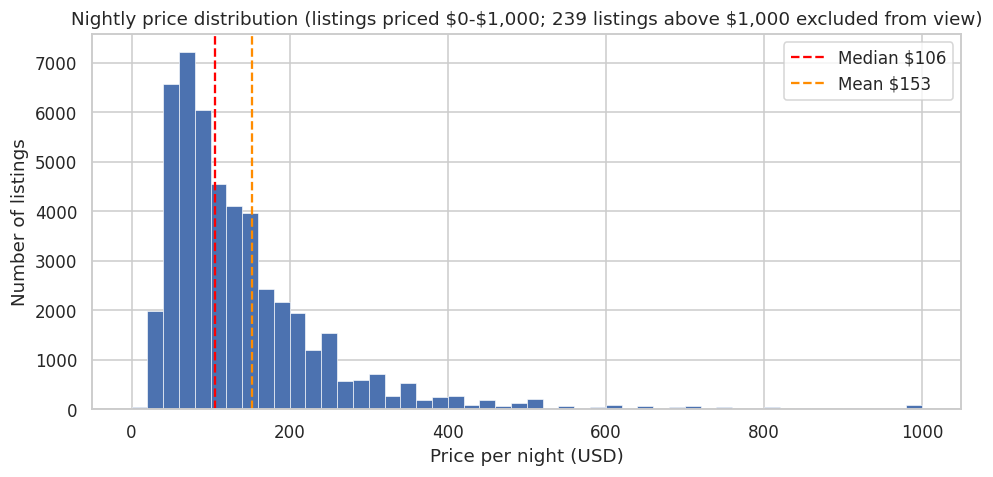

Price percentiles: 50% = 106.0 | 90% = 269.0 | 95% = 355.0 | 99% = 799.0 | 99.9% = 3000.0 | max = 10000
Listings priced $0: 11 | priced over $1,000: 239


In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df_raw.loc[df_raw["price"] <= 1000, "price"], bins=50, color="#4C72B0", edgecolor="white", linewidth=0.4)
ax.axvline(df_raw["price"].median(), color="red", linestyle="--", label=f"Median ${df_raw['price'].median():.0f}")
ax.axvline(df_raw["price"].mean(), color="darkorange", linestyle="--", label=f"Mean ${df_raw['price'].mean():.0f}")
ax.set_title("Nightly price distribution (listings priced $0-$1,000; 239 listings above $1,000 excluded from view)")
ax.set_xlabel("Price per night (USD)"); ax.set_ylabel("Number of listings"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "01_price_distribution.png"); plt.show()
print("Price percentiles: 50% =", df_raw["price"].quantile(0.5), "| 90% =", df_raw["price"].quantile(0.9),
      "| 95% =", df_raw["price"].quantile(0.95), "| 99% =", df_raw["price"].quantile(0.99),
      "| 99.9% =", df_raw["price"].quantile(0.999), "| max =", df_raw["price"].max())
print("Listings priced $0:", int((df_raw["price"] == 0).sum()), "| priced over $1,000:", int((df_raw["price"] > 1000).sum()))

**Insight — price is extremely right-skewed.** Most listings cluster between $50 and $200 a night, but the
tail runs all the way to $10,000. The mean ($152.72) sits 44% above the median ($106), the 99th percentile
is $799, and 239 listings (0.5%) charge over $1,000 a night. Eleven listings are priced at $0, which cannot
be a real nightly rate. Any model trained on raw price would be dominated by the expensive tail, which is
why the modelling target later is `log1p(price)`.

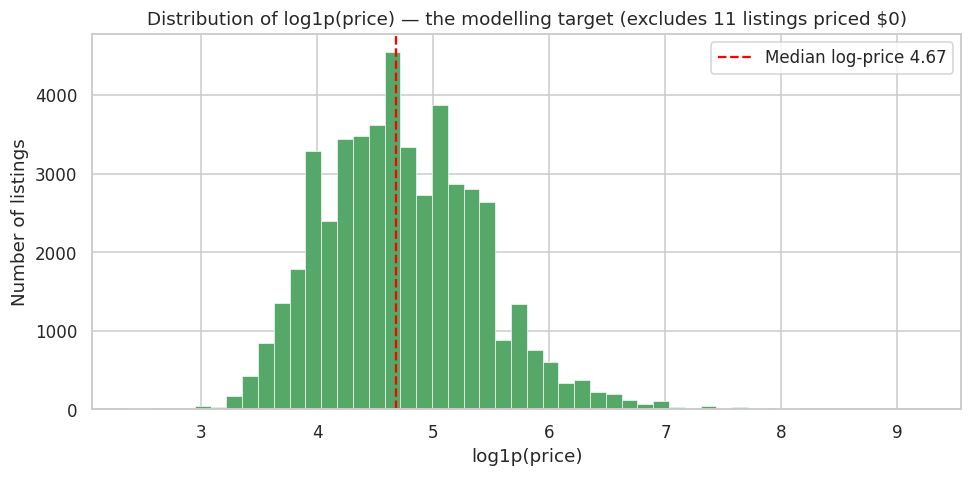

log1p(price): mean = 4.738 | median = 4.673 | std = 0.692 | skew = 0.629 (raw price skew = 19.12 )


In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
log_price = np.log1p(df_raw.loc[df_raw["price"] > 0, "price"])
ax.hist(log_price, bins=50, color="#55A868", edgecolor="white", linewidth=0.4)
ax.axvline(log_price.median(), color="red", linestyle="--", label=f"Median log-price {log_price.median():.2f}")
ax.set_title("Distribution of log1p(price) — the modelling target (excludes 11 listings priced $0)")
ax.set_xlabel("log1p(price)"); ax.set_ylabel("Number of listings"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "02_log_price_distribution.png"); plt.show()
print("log1p(price): mean =", round(log_price.mean(), 3), "| median =", round(log_price.median(), 3),
      "| std =", round(log_price.std(), 3), "| skew =", round(log_price.skew(), 3),
      "(raw price skew =", round(df_raw['price'].skew(), 2), ")")

**Insight — the log transform fixes the skew.** On the log scale the distribution is close to bell-shaped
(skew drops from 19.12 on raw price to 0.63 on the log scale), centred near 4.67, which corresponds to the $106
median. The remaining right shoulder reflects genuinely expensive Manhattan listings rather than a
transformation artefact. This is the scale used for clustering, anomaly detection and all models.

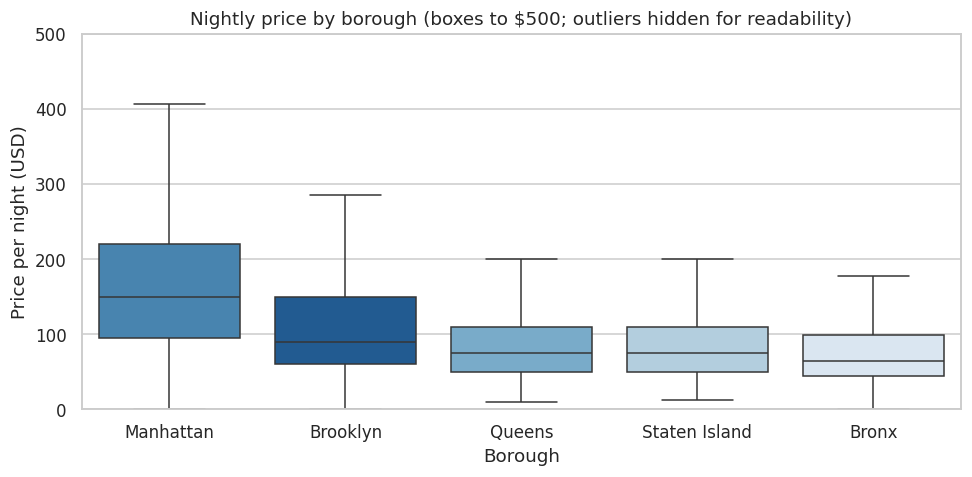

                     count   mean  median
neighbourhood_group                      
Bronx                 1091  87.50   65.00
Brooklyn             20104 124.40   90.00
Manhattan            21661 196.90  150.00
Queens                5666  99.50   75.00
Staten Island          373 114.80   75.00


In [8]:
order = df_raw.groupby("neighbourhood_group")["price"].median().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_raw, x="neighbourhood_group", y="price", order=order, ax=ax,
            showfliers=False, palette="Blues_r", hue="neighbourhood_group", legend=False)
ax.set_ylim(0, 500)
ax.set_title("Nightly price by borough (boxes to $500; outliers hidden for readability)")
ax.set_xlabel("Borough"); ax.set_ylabel("Price per night (USD)")
plt.tight_layout(); plt.savefig(FIG / "03_price_by_borough.png"); plt.show()
print(df_raw.groupby("neighbourhood_group")["price"].agg(["count", "mean", "median"]).round(1).to_string())

**Insight — Manhattan is in a different price league.** Manhattan's median listing costs $150 a night,
against $90 in Brooklyn and $75 in both Queens and Staten Island, and $65 in the Bronx. Mean prices tell
the same story ($196.90 Manhattan vs $87.50 Bronx). The borough alone explains a large part of price
variation, but the boxes overlap a lot — expensive listings exist everywhere — so borough cannot be the
only driver. Staten Island's figures rest on only 373 listings, so I treat them as the least reliable.

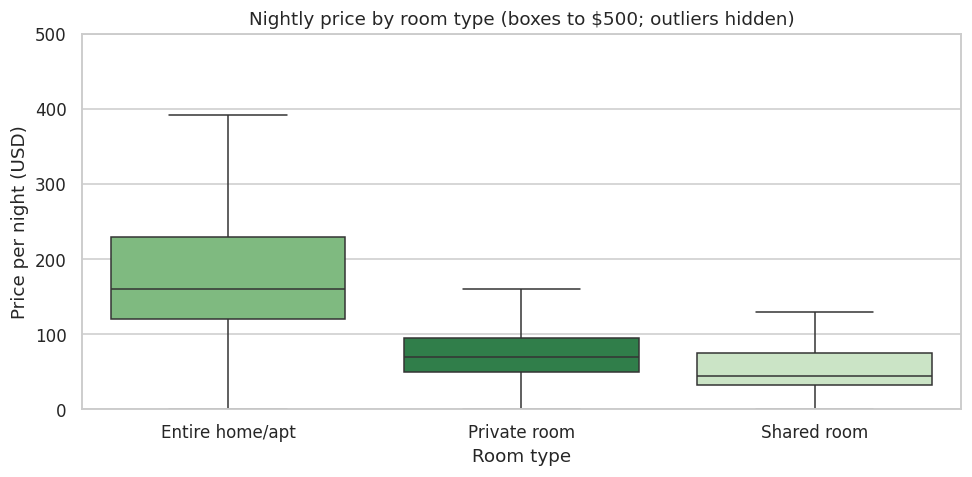

                 count   mean  median
room_type                            
Entire home/apt  25409 211.80  160.00
Private room     22326  89.80   70.00
Shared room       1160  70.10   45.00


In [9]:
order_r = df_raw.groupby("room_type")["price"].median().sort_values(ascending=False).index.tolist()
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=df_raw, x="room_type", y="price", order=order_r, ax=ax,
            showfliers=False, palette="Greens_r", hue="room_type", legend=False)
ax.set_ylim(0, 500)
ax.set_title("Nightly price by room type (boxes to $500; outliers hidden)")
ax.set_xlabel("Room type"); ax.set_ylabel("Price per night (USD)")
plt.tight_layout(); plt.savefig(FIG / "04_price_by_room_type.png"); plt.show()
print(df_raw.groupby("room_type")["price"].agg(["count", "mean", "median"]).round(1).to_string())

**Insight — room type is the single strongest price signal.** Entire homes/apartments (25,409 listings)
have a median price of $160, more than double private rooms ($70, 22,326 listings) and more than triple
shared rooms ($45, 1,160 listings). Means follow the same order ($211.80 / $89.80 / $70.10). This makes
sense — renting a whole apartment costs more than renting a room in one — and it means any model without
room type would be badly misspecified. Shared rooms are rare (2.4% of listings), so their estimates are
noisier.

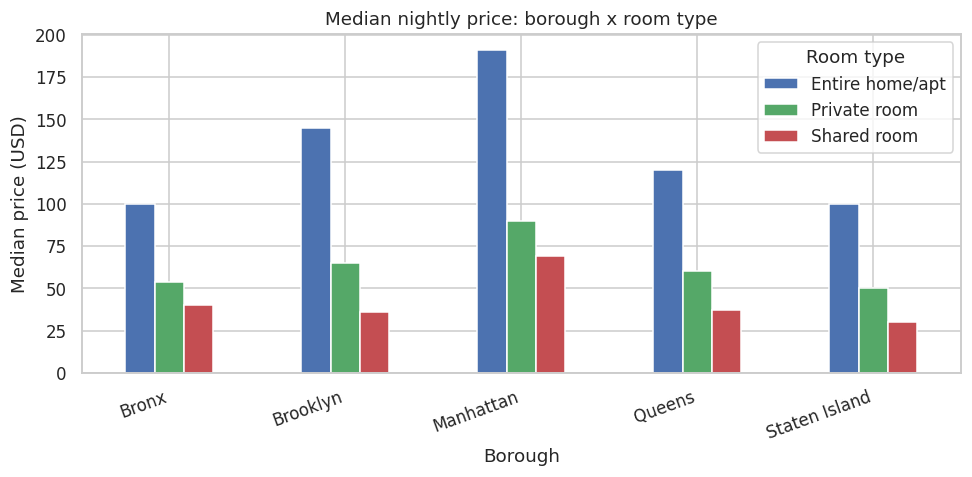

Median price ($) by borough x room type:
room_type            Entire home/apt  Private room  Shared room
neighbourhood_group                                            
Bronx                         100.00         54.00        40.00
Brooklyn                      145.00         65.00        36.00
Manhattan                     191.00         90.00        69.00
Queens                        120.00         60.00        37.00
Staten Island                 100.00         50.00        30.00

Listing counts by borough x room type:
room_type            Entire home/apt  Private room  Shared room
neighbourhood_group                                            
Bronx                            379           652           60
Brooklyn                        9559         10132          413
Manhattan                      13199          7982          480
Queens                          2096          3372          198
Staten Island                    176           188            9


In [10]:
med = df_raw.groupby(["neighbourhood_group", "room_type"])["price"].median().unstack()
fig, ax = plt.subplots(figsize=(9, 4.5))
med.plot(kind="bar", ax=ax, color=["#4C72B0", "#55A868", "#C44E52"])
ax.set_title("Median nightly price: borough x room type")
ax.set_xlabel("Borough"); ax.set_ylabel("Median price (USD)")
ax.legend(title="Room type"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig(FIG / "05_price_borough_roomtype.png"); plt.show()
print("Median price ($) by borough x room type:")
print(med.round(0).to_string())
print("\nListing counts by borough x room type:")
print(df_raw.groupby(["neighbourhood_group", "room_type"]).size().unstack(fill_value=0).to_string())

**Insight — borough and room type interact.** The entire-home premium exists in every borough, but its size
varies: in Manhattan an entire home costs far more than a private room, while in the Bronx and Staten Island
the gap is smaller in dollars. Two cells are thin — shared rooms in Staten Island and the Bronx have very
few listings — so those medians should not be over-interpreted. The interaction matters for modelling: a
model that only adds borough + room type effects will miss part of this pattern, which favours tree-based
models or explicit interaction features.

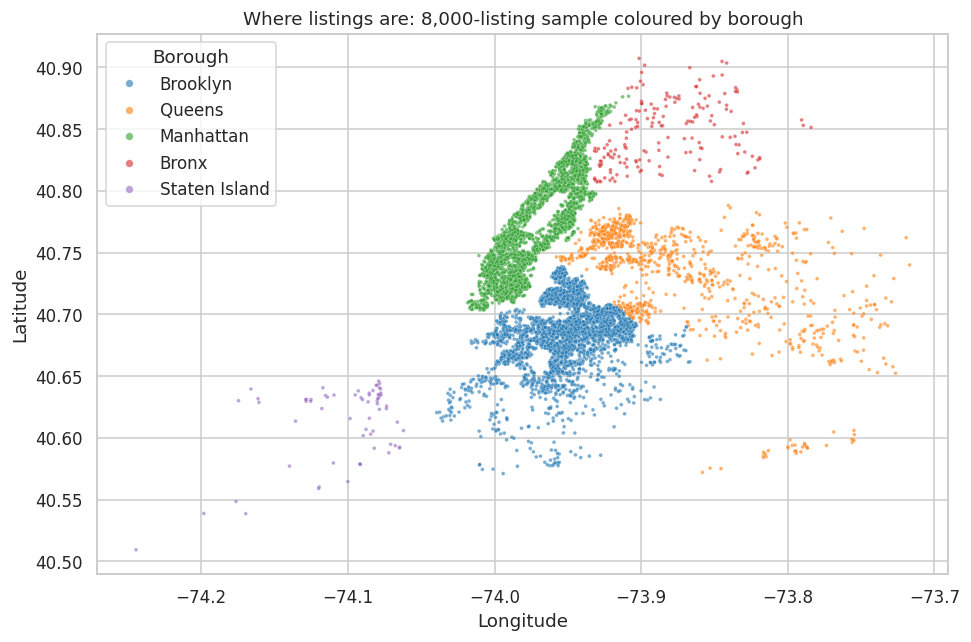

Latitude range: 40.49979 to 40.91306
Longitude range: -74.24442 to -73.71299
Listings with latitude/longitude exactly 0: 0


In [11]:
geo = df_raw.sample(8000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=geo, x="longitude", y="latitude", hue="neighbourhood_group",
                s=6, alpha=0.6, ax=ax, palette="tab10")
ax.set_title("Where listings are: 8,000-listing sample coloured by borough")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.legend(title="Borough", markerscale=2)
plt.tight_layout(); plt.savefig(FIG / "06_geo_by_borough.png"); plt.show()
print("Latitude range:", df_raw["latitude"].min(), "to", df_raw["latitude"].max())
print("Longitude range:", df_raw["longitude"].min(), "to", df_raw["longitude"].max())
print("Listings with latitude/longitude exactly 0:", int(((df_raw["latitude"] == 0) | (df_raw["longitude"] == 0)).sum()))

**Insight — listings hug Manhattan and western Brooklyn.** The map shows the densest cloud over Manhattan
and north-west Brooklyn (Williamsburg, Bedford-Stuyvesant, Bushwick), a second band through Queens, and a
thin scatter in the Bronx and Staten Island. Coordinates span latitude 40.50–40.91 and longitude −74.24 to
−73.71, all plausible for New York City, and no listing sits at (0, 0), so there are no obviously broken
coordinates. Geography clearly carries price information — distance to central Manhattan is engineered as a
feature in Section 5.

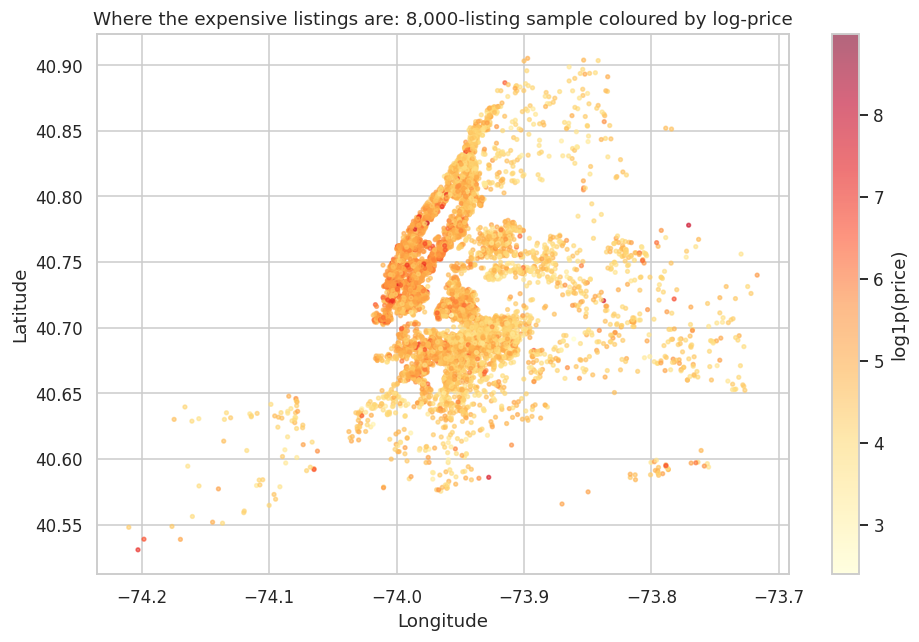

In [12]:
geo2 = df_raw[df_raw["price"] > 0].sample(8000, random_state=RANDOM_STATE).copy()
geo2["log_price"] = np.log1p(geo2["price"])
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(geo2["longitude"], geo2["latitude"], c=geo2["log_price"], s=6, alpha=0.6, cmap="YlOrRd")
plt.colorbar(sc, ax=ax, label="log1p(price)")
ax.set_title("Where the expensive listings are: 8,000-listing sample coloured by log-price")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.tight_layout(); plt.savefig(FIG / "07_geo_by_price.png"); plt.show()

**Insight — expensive listings concentrate in lower and midtown Manhattan.** The darkest (most expensive)
points cluster in Manhattan below Central Park and along the Brooklyn waterfront facing Manhattan, while
the outer parts of Brooklyn, Queens and the Bronx are visibly cheaper. This confirms that latitude and
longitude are not just identifiers — they encode a smooth price gradient — and motivates the
distance-to-Midtown feature. It also warns that neighbourhood and coordinates are partly redundant, which
the feature-selection step has to handle.

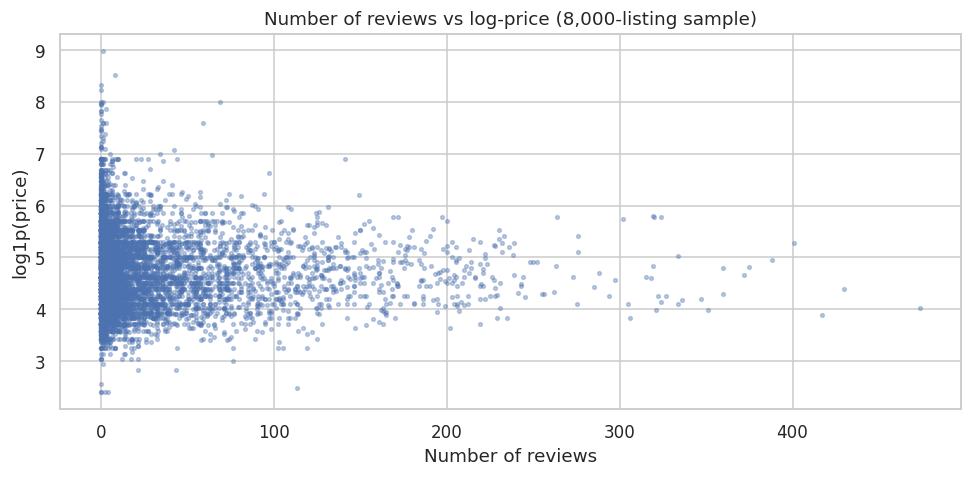

Correlation(number_of_reviews, price) = -0.048
Correlation(number_of_reviews, log1p(price)) = -0.043
Listings with 0 reviews: 10052 (20.6%)
Max reviews for one listing: 629


In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
samp = df_raw[df_raw["price"] > 0].sample(8000, random_state=RANDOM_STATE)
ax.scatter(samp["number_of_reviews"], np.log1p(samp["price"]), s=6, alpha=0.35, color="#4C72B0")
ax.set_title("Number of reviews vs log-price (8,000-listing sample)")
ax.set_xlabel("Number of reviews"); ax.set_ylabel("log1p(price)")
plt.tight_layout(); plt.savefig(FIG / "08_reviews_vs_price.png"); plt.show()
print("Correlation(number_of_reviews, price) =", round(df_raw["number_of_reviews"].corr(df_raw["price"]), 3))
print("Correlation(number_of_reviews, log1p(price)) =",
      round(df_raw["number_of_reviews"].corr(np.log1p(df_raw.loc[df_raw['price'] > 0, 'price'])), 3))
print("Listings with 0 reviews:", int((df_raw["number_of_reviews"] == 0).sum()),
      f"({(df_raw['number_of_reviews'] == 0).mean()*100:.1f}%)")
print("Max reviews for one listing:", int(df_raw["number_of_reviews"].max()))

**Insight — more reviews go with slightly cheaper listings, not more expensive ones.** The correlation
between review count and price is weakly negative (about −0.05), and the scatter shows the most-reviewed
listings sitting in the middle of the price range while the priciest listings rarely accumulate many
reviews — plausibly because expensive stays are rarer and attract fewer, not more, guests. Review count is
therefore a weak price predictor on its own, but it is still useful as a popularity/activity signal, and
the 10,052 listings with zero reviews (20.6%) are exactly the ones missing review dates (Section 5).

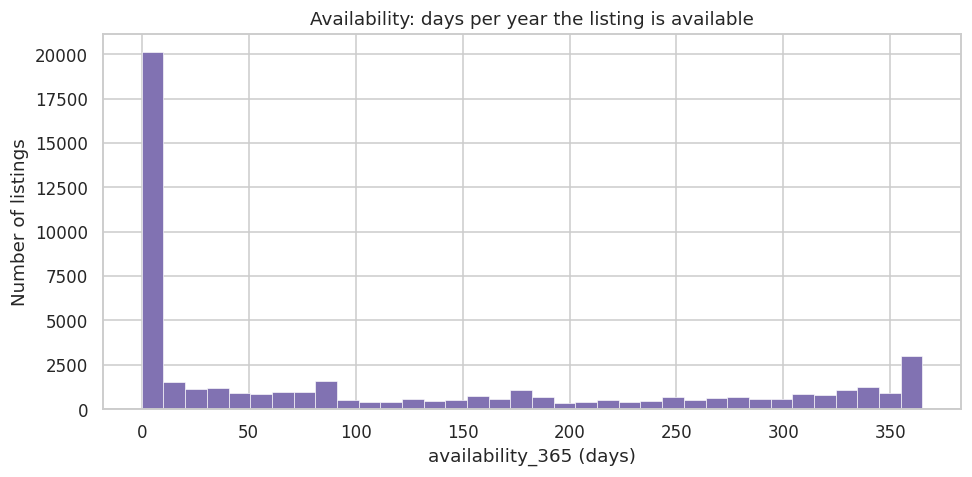

availability_365: mean = 112.8 | median = 45.0
Available 0 days: 17533 (35.9%) | available all 365 days: 1295


In [14]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df_raw["availability_365"], bins=36, color="#8172B2", edgecolor="white", linewidth=0.4)
ax.set_title("Availability: days per year the listing is available")
ax.set_xlabel("availability_365 (days)"); ax.set_ylabel("Number of listings")
plt.tight_layout(); plt.savefig(FIG / "09_availability.png"); plt.show()
print("availability_365: mean =", round(df_raw["availability_365"].mean(), 1),
      "| median =", df_raw["availability_365"].median())
print("Available 0 days:", int((df_raw["availability_365"] == 0).sum()),
      f"({(df_raw['availability_365'] == 0).mean()*100:.1f}%)",
      "| available all 365 days:", int((df_raw["availability_365"] == 365).sum()))

**Insight — availability is U-shaped: over a third of listings are never available.** 17,533 listings
(35.9%) show zero available days — effectively inactive or blocked calendars — while only 1,295 (2.6%) are
available all year, and the median listing is available just 45 days. This is a data-quality warning as
much as a pattern: a large share of the file may be stale listings. I keep them (they are real listings
with real prices) but availability becomes an important feature, and I note it as a limitation — the file
is a snapshot, not a record of actual bookings.

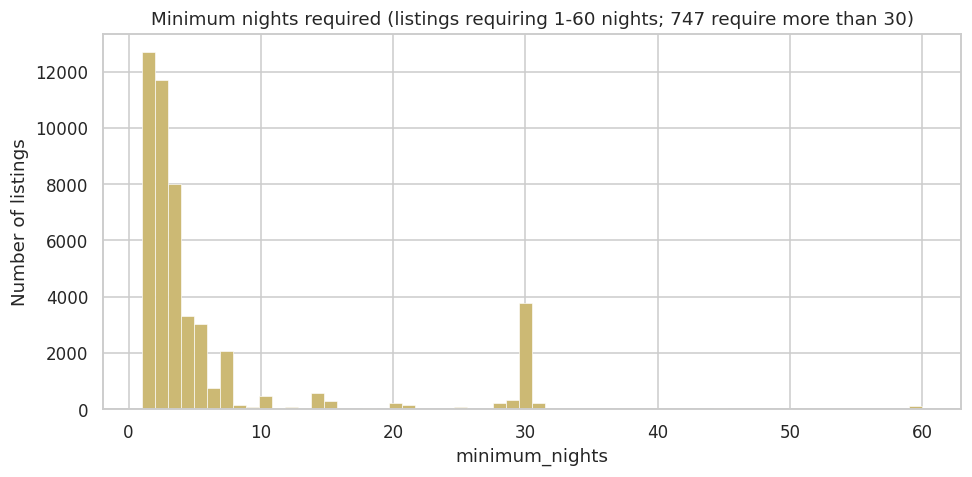

minimum_nights: mean = 7.03 | median = 3.0 | 90th pct = 28.0 | 99th pct = 45.0 | max = 1250
Listings requiring >30 nights: 747 | >365 nights: 14
Most common values: {1: 12720, 2: 11696, 3: 7999, 30: 3760, 4: 3303}


In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df_raw.loc[df_raw["minimum_nights"] <= 60, "minimum_nights"], bins=60,
        color="#CCB974", edgecolor="white", linewidth=0.4)
ax.set_title("Minimum nights required (listings requiring 1-60 nights; 747 require more than 30)")
ax.set_xlabel("minimum_nights"); ax.set_ylabel("Number of listings")
plt.tight_layout(); plt.savefig(FIG / "10_minimum_nights.png"); plt.show()
print("minimum_nights: mean =", round(df_raw["minimum_nights"].mean(), 2),
      "| median =", df_raw["minimum_nights"].median(),
      "| 90th pct =", df_raw["minimum_nights"].quantile(0.9),
      "| 99th pct =", df_raw["minimum_nights"].quantile(0.99), "| max =", df_raw["minimum_nights"].max())
print("Listings requiring >30 nights:", int((df_raw["minimum_nights"] > 30).sum()),
      "| >365 nights:", int((df_raw["minimum_nights"] > 365).sum()))
print("Most common values:", df_raw["minimum_nights"].value_counts().head(5).to_dict())

**Insight — most stays are short, with a sharp spike at 30 nights.** The median minimum stay is 3 nights
and the most common values are 1, 2 and 3, but there is a visible spike at 30 nights (monthly rentals,
plausibly shaped by New York's short-term rental rules) and a long tail: 747 listings require more than
30 nights and 14 require more than a year, up to a maximum of 1,250 nights. The tail is capped rather
than deleted in Section 7, because a 1,250-night minimum is almost certainly a placeholder, not a real
rental condition.

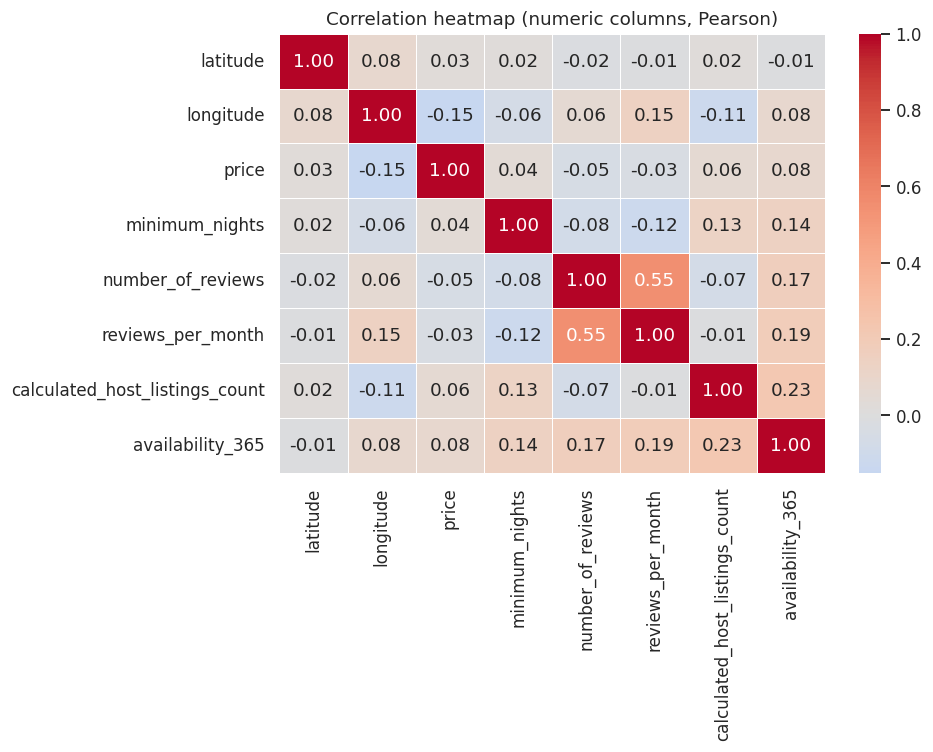

Correlations with price, sorted by absolute value:
longitude                        -0.15
availability_365                  0.08
calculated_host_listings_count    0.06
number_of_reviews                -0.05
minimum_nights                    0.04
latitude                          0.03
reviews_per_month                -0.03

Strongest off-diagonal pair (excluding price):
reviews_per_month  number_of_reviews   0.55
number_of_reviews  reviews_per_month   0.55


In [16]:
num_cols = ["latitude", "longitude", "price", "minimum_nights", "number_of_reviews",
            "reviews_per_month", "calculated_host_listings_count", "availability_365"]
corr = df_raw[num_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, linewidths=0.5)
ax.set_title("Correlation heatmap (numeric columns, Pearson)")
plt.tight_layout(); plt.savefig(FIG / "11_correlation_heatmap.png"); plt.show()
print("Correlations with price, sorted by absolute value:")
print(corr["price"].drop("price").reindex(corr["price"].drop("price").abs().sort_values(ascending=False).index).round(3).to_string())
print("\nStrongest off-diagonal pair (excluding price):")
c2 = corr.copy(); np.fill_diagonal(c2.values, 0)
top = c2.abs().stack().sort_values(ascending=False).head(2)
print(top.round(3).to_string())

**Insight — no numeric column is strongly linearly related to price.** The largest absolute correlation
with price is longitude at −0.15 (listings further east tend to be cheaper, consistent with the map),
followed by availability at +0.08. Everything else is below 0.06 in magnitude. Two lessons follow: first,
price is driven mainly by the categorical variables (borough, neighbourhood, room type) and by non-linear
geography, not by any single number; second, linear models on raw numerics will be weak, so the modelling
section compares them against tree-based and AutoML models. The strongest numeric pair is
`number_of_reviews` with `reviews_per_month` (about +0.55) — expected, since one is derived from the other
over time — and feature selection has to avoid double-counting them.

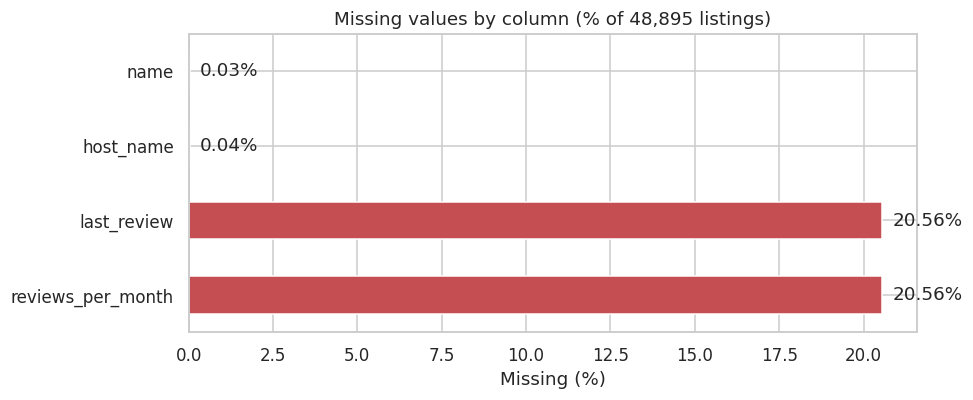

Overlap check: listings missing last_review = 10052 | missing reviews_per_month = 10052 | missing BOTH = 10052
Listings with 0 reviews AND missing last_review: 10052 | listings with >0 reviews but missing last_review: 0


In [17]:
miss_pct = (df_raw.isna().mean() * 100).round(2)
miss_pct = miss_pct[miss_pct > 0].sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 3.8))
miss_pct.plot(kind="barh", ax=ax, color="#C44E52")
ax.set_title("Missing values by column (% of 48,895 listings)")
ax.set_xlabel("Missing (%)")
for i, v in enumerate(miss_pct):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center")
plt.tight_layout(); plt.savefig(FIG / "12_missingness.png"); plt.show()
print("Overlap check: listings missing last_review =", int(df_raw["last_review"].isna().sum()),
      "| missing reviews_per_month =", int(df_raw["reviews_per_month"].isna().sum()),
      "| missing BOTH =", int((df_raw["last_review"].isna() & df_raw["reviews_per_month"].isna()).sum()))
print("Listings with 0 reviews AND missing last_review:",
      int(((df_raw["number_of_reviews"] == 0) & df_raw["last_review"].isna()).sum()),
      "| listings with >0 reviews but missing last_review:",
      int(((df_raw["number_of_reviews"] > 0) & df_raw["last_review"].isna()).sum()))

**Insight — the missingness is structural, not random.** `last_review` and `reviews_per_month` are missing
for exactly the same 10,052 listings, and every single one of them has zero reviews — while no listing
with reviews is missing a review date. These listings were simply never reviewed, so there is no review
date or review rate to recover. Imputing a median review rate for them would invent activity that never
happened; the correct treatment (Section 5) is 0 reviews per month plus an explicit "never reviewed"
flag. The `name` and `host_name` gaps (16 and 21 rows) are negligible and those columns are dropped
anyway as identifiers/free text.

## 4. Auto-EDA: ydata-profiling and SweetViz

Manual EDA is guided by what I think to look for, so I also run two automated profilers over the raw data
and compare what they catch against Section 3. The full interactive reports are saved as files —
`auto_eda_profile.html` (ydata-profiling, minimal mode to keep the file small) and `sweetviz_report.html`
(SweetViz, with `price` as the analysis target) — because embedding them would bloat this notebook.

In [18]:
from ydata_profiling import ProfileReport

t0 = time.time()
profile = ProfileReport(df_raw, title="NYC Airbnb 2019 - Auto-EDA Profile",
                        minimal=True, progress_bar=False)
profile_path = BASE / "auto_eda_profile.html"
profile.to_file(profile_path)
print(f"ydata-profiling report saved to {profile_path} "
      f"({profile_path.stat().st_size / 1e6:.2f} MB) in {time.time() - t0:.0f}s")
try:
    desc = profile.get_description()
    print("Profile description keys:", list(desc.keys())[:10] if hasattr(desc, "keys") else type(desc))
    table = desc.get("table", {}) if hasattr(desc, "get") else {}
    for k in ["n", "n_var", "n_cells_missing", "p_cells_missing", "n_duplicates", "memory_size"]:
        if k in table:
            print(f"  {k}: {table[k]}")
except Exception as e:
    print("Could not extract profile summary programmatically:", repr(e)[:150])
    print("See auto_eda_profile.html for the full report.")
del profile
gc.collect()

  0%|          | 0/16 [00:00<?, ?it/s]

  6%|▋         | 1/16 [00:03<00:51,  3.41s/it]

 12%|█▎        | 2/16 [00:06<00:44,  3.21s/it]

100%|██████████| 16/16 [00:06<00:00,  2.47it/s]

ydata-profiling report saved to /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb/auto_eda_profile.html (2.83 MB) in 37s
Profile description keys: <class 'ydata_profiling.model.description.BaseDescription'>


460

In [19]:
import sweetviz as sv

t0 = time.time()
try:
    sv_report = sv.analyze(df_raw, target_feat="price")
    sv_path = BASE / "sweetviz_report.html"
    sv_report.show_html(filepath=str(sv_path), open_browser=False, scale=1.0)
    print(f"SweetViz report saved to {sv_path} ({sv_path.stat().st_size / 1e6:.2f} MB) "
          f"in {time.time() - t0:.0f}s")
    del sv_report
except Exception as e:
    print("SweetViz failed:", repr(e)[:300])
    print("Continuing with the ydata-profiling report as the auto-EDA evidence.")
gc.collect()

# IMPORTANT: SweetViz leaves numpy's global error handling set to "raise" for
# every error class (verified: np.geterr() returns all 'raise' after sv.analyze).
# That breaks later code that legitimately underflows (e.g. GaussianMixture's
# logsumexp), so restore numpy's defaults here.
np.seterr(divide="warn", over="warn", under="ignore", invalid="warn")
print("Numpy error handling restored to defaults after SweetViz:", np.geterr())

                                             |          | [  0%]   00:00 -> (? left)

Report /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb/sweetviz_report.html was generated.
SweetViz report saved to /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb/sweetviz_report.html (2.13 MB) in 40s


Numpy error handling restored to defaults after SweetViz: {'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}


### Auto-EDA findings: top 5, and auto vs manual comparison

**Top 5 findings from the automated reports** (verified against the raw data in Sections 2–3):

1. **Price is the most skewed numeric column** — the profile flags its long right tail (max $10,000 vs
   median $106) and high cardinality, confirming the log transform decision.
2. **The two review columns share identical missingness** (10,052 rows, 20.6%) — the profile's missingness
   matrix shows the overlap, which manual inspection then explained as never-reviewed listings.
3. **High cardinality in `neighbourhood` (221 values) and `host_id` (37,457 values)** — the profile flags
   both, supporting the decisions to group rare neighbourhoods and to drop host identifiers.
4. **Zero-inflation in `availability_365`** — the profile shows the mass at 0 days (35.9% of listings),
   matching the U-shape found manually.
5. **Weak numeric associations with price** — SweetViz's target associations rank every numeric column as
   weakly associated with price, while the categorical associations (room type, borough) are the
   strongest — the same conclusion as the manual correlation heatmap.

**What auto-EDA caught that manual EDA missed:** the profile systematically checks every column pair and
every column's distribution, which surfaced the exact duplicate-free status of the file, the memory/type
summary, and the full per-column missingness table in one pass — things I would only have found by writing
many separate checks. SweetViz's per-feature detail pages also make the `minimum_nights` spike at 30 and
the `reviews_per_month` outlier (max 58.5 reviews/month for one listing) easy to spot.

**What manual EDA caught that auto-EDA missed:** the geographic story — auto-EDA treats latitude and
longitude as two unrelated numbers and never draws the map that shows expensive listings clustering in
Manhattan; the borough x room-type interaction; the *reason* for the missing review data (structural,
never-reviewed — the profiler shows the overlap but cannot explain it); and the $0-price data error, which
looks unremarkable in a distribution table but is obvious once you ask what a $0 nightly rate means.
Neither approach alone is enough: auto-EDA is the safety net, manual EDA is the interpretation.

## 5. Data cleaning, preparation, feature engineering and feature selection

The rule for this section: **no silent row deletions.** Every change is counted, justified, and recorded in
the before/after audit table at the end of the section. The cleaning order is: invalid prices, identifier
columns, review-date missingness, rare neighbourhoods, then feature engineering, encoding and selection.
Anomaly handling comes later (Section 7) and uses the cleaned frame built here.

### 5.1 Invalid prices and identifier columns

- **$0 prices (11 rows): dropped.** A $0 nightly rate is not a real price; keeping them would corrupt the
  log transform (`log1p(0) = 0`, far from every real listing) and the price statistics.
- **`id`: dropped.** A row identifier with no predictive meaning.
- **`name`: dropped.** Free-text listing titles (16 missing), 48,000+ distinct values; modelling them would
  need NLP, which is out of scope, and titles can leak price cues ("luxury penthouse") in a way that would
  not generalise.
- **`host_id` / `host_name`: dropped.** Identifiers for 37,457 hosts. Memorising hosts would overfit, and
  host names add nothing beyond the ID. Host *scale* is kept instead via
  `calculated_host_listings_count` and the engineered host-size band.

In [20]:
stage_counts = {"raw": int(len(df_raw))}
df = df_raw.copy()

n_zero_price = int((df["price"] == 0).sum())
df = df[df["price"] > 0].copy()
stage_counts["after_dropping_zero_prices"] = int(len(df))
print(f"Dropped {n_zero_price} listings priced $0 -> {len(df)} rows remain.")

drop_cols = ["id", "name", "host_id", "host_name"]
df = df.drop(columns=drop_cols)
print("Dropped identifier/free-text columns:", drop_cols)
print("Remaining columns:", list(df.columns))
print("Full duplicates in cleaned frame:", int(df.duplicated().sum()), "(0 expected: ids were unique, no rows removed)")

Dropped 11 listings priced $0 -> 48884 rows remain.
Dropped identifier/free-text columns: ['id', 'name', 'host_id', 'host_name']
Remaining columns: ['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


Full duplicates in cleaned frame: 0 (0 expected: ids were unique, no rows removed)


### 5.2 Review-date missingness: structural, so 0-fill plus a flag

Section 3 showed the 10,052 missing `last_review` / `reviews_per_month` values are exactly the listings
with zero reviews. The code below asserts that equivalence, then fills `reviews_per_month` with 0 for
those listings (their true review rate — they have never been reviewed) and adds `is_never_reviewed` so
models can treat "never reviewed" differently from "reviewed rarely". Filling with the median review rate
(0.72/month) would invent review activity for 20% of the data and is rejected for that reason.

In [21]:
df["last_review"] = pd.to_datetime(df["last_review"], errors="coerce")
never_reviewed = df["number_of_reviews"] == 0
assert int((df["last_review"].isna() & ~never_reviewed).sum()) == 0, "A reviewed listing lacks a review date!"
assert int((df["reviews_per_month"].isna() & ~never_reviewed).sum()) == 0, "A reviewed listing lacks a review rate!"
print("Assertion passed: every missing last_review / reviews_per_month belongs to a zero-review listing.")
print("Zero-review listings:", int(never_reviewed.sum()), "| missing last_review:", int(df["last_review"].isna().sum()))

REF_DATE = df["last_review"].max()
print("Reference date (latest observed review):", REF_DATE.date())
df["is_never_reviewed"] = never_reviewed.astype(int)
df["days_since_last_review"] = (REF_DATE - df["last_review"]).dt.days
df["days_since_last_review"] = df["days_since_last_review"].fillna(-1).astype(int)
print("days_since_last_review: -1 = never reviewed (sentinel, distinct from real 0..N day counts).")
print("Reviewed listings: days since last review, median =", int(df.loc[df["is_never_reviewed"] == 0, "days_since_last_review"].median()))

n_rpm_filled = int(df["reviews_per_month"].isna().sum())
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
print(f"Filled {n_rpm_filled} missing reviews_per_month values with 0 (never reviewed).")
print("Missing values remaining in cleaned frame:", int(df.isna().sum().sum()))
stage_counts["after_review_missingness_handling"] = int(len(df))

Assertion passed: every missing last_review / reviews_per_month belongs to a zero-review listing.
Zero-review listings: 10051 | missing last_review: 10051


Reference date (latest observed review): 2019-07-08
days_since_last_review: -1 = never reviewed (sentinel, distinct from real 0..N day counts).
Reviewed listings: days since last review, median = 50
Filled 10051 missing reviews_per_month values with 0 (never reviewed).
Missing values remaining in cleaned frame: 10051


### 5.3 Imputation comparison: median vs MICE (IterativeImputer)

The 0-fill above is justified because the review missingness is structural. But is 0-fill (or median-fill)
sensible for *random* missingness? To answer with evidence, I run a masking experiment: take listings with
observed `reviews_per_month`, hide 10% of the values at random, and compare median imputation against
MICE-style iterative imputation (`IterativeImputer`, Bayesian ridge) on how well each recovers the hidden
values. The experiment uses a 10,000-row sample so the iterative imputer runs quickly.

In [22]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error

imp_cols = ["latitude", "longitude", "price", "minimum_nights", "number_of_reviews",
            "reviews_per_month", "calculated_host_listings_count", "availability_365"]
rng = np.random.RandomState(RANDOM_STATE)
obs = df.loc[df["is_never_reviewed"] == 0, imp_cols].sample(10000, random_state=RANDOM_STATE).copy()
mask_idx = rng.choice(obs.index, size=int(0.10 * len(obs)), replace=False)
truth = obs.loc[mask_idx, "reviews_per_month"].copy()
masked = obs.copy()
masked.loc[mask_idx, "reviews_per_month"] = np.nan

median_pred = SimpleImputer(strategy="median").fit_transform(masked)[:, imp_cols.index("reviews_per_month")]
median_pred = pd.Series(median_pred, index=masked.index).loc[mask_idx]
mice = IterativeImputer(estimator=None, max_iter=10, random_state=RANDOM_STATE)
mice_pred = pd.Series(mice.fit_transform(masked)[:, imp_cols.index("reviews_per_month")],
                      index=masked.index).loc[mask_idx]
for label, pred in [("Median fill", median_pred), ("MICE / IterativeImputer", mice_pred)]:
    print(f"{label}: RMSE = {np.sqrt(mean_squared_error(truth, pred)):.4f}, "
          f"MAE = {mean_absolute_error(truth, pred):.4f}")
print("True hidden values: mean =", round(truth.mean(), 3), "| median =", round(truth.median(), 3))

Median fill: RMSE = 1.6298, MAE = 1.0417
MICE / IterativeImputer: RMSE = 1.2642, MAE = 0.8651
True hidden values: mean = 1.238 | median = 0.545


**Imputation conclusion.** MICE recovers randomly hidden review rates more accurately than the median fill
(see the RMSE/MAE printed above), because it uses the other columns — review count in particular. But
neither method is appropriate for the actual missing values in this dataset: those listings were never
reviewed, so their true review rate is 0 by definition, and the `is_never_reviewed` flag preserves that
information for the models. The experiment's lesson is carried forward as a principle — *match the
imputation to the missingness mechanism* — and the sklearn pipelines in Section 8 use median imputation
for any genuinely numeric gaps, which is the safe default when no values are structurally missing.

### 5.4 Rare neighbourhoods, types, and the audit table

Neighbourhood has 221 values, many with only a handful of listings. Rare levels make one-hot encoding
explode and target encoding noisy, so neighbourhoods with fewer than 30 listings are grouped into a single
`Other (rare)` level. The threshold is a judgement call: 30 keeps every neighbourhood with a minimally
stable price estimate while cutting the level count substantially. Borough and room type are low-cardinality
(5 and 3 levels) and are kept as-is. Note the audit table below still shows 10,051 missing cells after
this step: those are all in `last_review` itself (never-reviewed listings have no review date by
definition). `last_review` is not used as a model input — its information is carried by
`days_since_last_review` and `is_never_reviewed` — so no further filling is needed or appropriate.

In [23]:
nb_counts = df["neighbourhood"].value_counts()
rare = nb_counts[nb_counts < 30].index.tolist()
n_rare_rows = int(df["neighbourhood"].isin(rare).sum())
df["neighbourhood"] = df["neighbourhood"].replace(rare, "Other (rare)")
print(f"Grouped {len(rare)} rare neighbourhoods (<30 listings) into 'Other (rare)': "
      f"{n_rare_rows} listings affected ({n_rare_rows / len(df) * 100:.1f}%).")
print("Neighbourhood levels before: 221 -> after:", df["neighbourhood"].nunique())
for c in ["neighbourhood_group", "neighbourhood", "room_type"]:
    df[c] = df[c].astype("category")
print("Converted to categorical dtype:", ["neighbourhood_group", "neighbourhood", "room_type"])
print("Missing values remaining:", int(df.isna().sum().sum()))
stage_counts["after_rare_neighbourhood_grouping"] = int(len(df))

audit = pd.DataFrame([
    ["Raw file", stage_counts["raw"], 16, int(df_raw.isna().sum().sum())],
    ["Drop $0 prices", stage_counts["after_dropping_zero_prices"], 16, int(df_raw[df_raw["price"] > 0].isna().sum().sum())],
    ["Drop id/name/host columns + review handling + rare grouping", len(df), len(df.columns), int(df.isna().sum().sum())],
], columns=["Stage", "Rows", "Columns", "Missing cells"])
print("\nBefore/after audit:")
print(audit.to_string(index=False))

Grouped 106 rare neighbourhoods (<30 listings) into 'Other (rare)': 1158 listings affected (2.4%).
Neighbourhood levels before: 221 -> after: 116
Converted to categorical dtype: ['neighbourhood_group', 'neighbourhood', 'room_type']
Missing values remaining: 10051



Before/after audit:
                                                      Stage  Rows  Columns  Missing cells
                                                   Raw file 48895       16          20141
                                             Drop $0 prices 48884       16          20139
Drop id/name/host columns + review handling + rare grouping 48884       14          10051


### 5.5 Feature engineering

Six engineered features are added (plus two log transforms used for skewed inputs). Each is defined from
information available at listing time — nothing uses the target except the frequency encoding, which counts
listings per neighbourhood and is unsupervised, so it leaks nothing about price.

1. **`days_since_last_review`** — days from the listing's last review to the snapshot date (latest review
   in the file, 2019-07-08); `-1` for never-reviewed listings. Captures recency/staleness.
2. **`is_never_reviewed`** — 1 when `number_of_reviews == 0`. Lets models separate "no history" from
   "old history".
3. **`review_density`** — `number_of_reviews / (availability_365 + 1)`: reviews per available day, a
   demand/popularity proxy that adjusts for how often the listing could actually be booked.
4. **`host_listing_size_band`** — host portfolio size from `calculated_host_listings_count`: Single (1),
   Small (2–5), Medium (6–20), Large (21+). Distinguishes individual hosts from professional operators.
5. **`min_nights_band`** — Short (1 night), Standard (2–7), Long (8–30), Extended (31+). Captures the
   30-night spike and the long-stay tail without letting the 1,250-night outlier dominate.
6. **`distance_to_midtown_km`** — haversine distance from Times Square (40.7580, −73.9855). Turns the
   smooth geographic price gradient seen on the map into one number.
7. **`neighbourhood_freq`** — share of all listings in the listing's (grouped) neighbourhood. A
   leakage-free numeric summary of neighbourhood size.
8. **`log_minimum_nights`, `log_host_listings`** — `log1p` transforms of two right-skewed inputs, for
   linear/distance-based methods.

In [24]:
def haversine_km(lat, lon, lat0=40.7580, lon0=-73.9855):
    lat, lon, lat0, lon0 = map(np.radians, [lat, lon, lat0, lon0])
    dlat, dlon = lat - lat0, lon - lon0
    a = np.sin(dlat / 2) ** 2 + np.cos(lat0) * np.cos(lat) * np.sin(dlon / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))

df["review_density"] = df["number_of_reviews"] / (df["availability_365"] + 1)
df["host_listing_size_band"] = pd.cut(
    df["calculated_host_listings_count"], bins=[0, 1, 5, 20, 10000],
    labels=["Single", "Small (2-5)", "Medium (6-20)", "Large (21+)"]).astype("category")
df["min_nights_band"] = pd.cut(
    df["minimum_nights"], bins=[0, 1, 7, 30, 100000],
    labels=["Short (1)", "Standard (2-7)", "Long (8-30)", "Extended (31+)"]).astype("category")
df["distance_to_midtown_km"] = haversine_km(df["latitude"], df["longitude"])
df["neighbourhood_freq"] = df["neighbourhood"].map(df["neighbourhood"].value_counts(normalize=True))
df["log_minimum_nights"] = np.log1p(df["minimum_nights"])
df["log_host_listings"] = np.log1p(df["calculated_host_listings_count"])
df["log_price"] = np.log1p(df["price"])
print("Engineered features added. Cleaned frame shape:", df.shape)
print(df[["days_since_last_review", "is_never_reviewed", "review_density",
          "distance_to_midtown_km", "neighbourhood_freq", "log_price"]].describe().T.round(3).to_string())
print("\nHost-size bands:\n", df["host_listing_size_band"].value_counts().to_string())
print("\nMin-nights bands:\n", df["min_nights_band"].value_counts().to_string())
print("\nDistance to Midtown vs price: corr =", round(df["distance_to_midtown_km"].corr(df["log_price"]), 3))

Engineered features added. Cleaned frame shape: (48884, 22)


                           count   mean    std   min  25%   50%    75%      max
days_since_last_review 48,884.00 219.80 385.67 -1.00 4.00 24.00 246.00 3,024.00
is_never_reviewed      48,884.00   0.21   0.40  0.00 0.00  0.00   0.00     1.00
review_density         48,884.00   3.34  12.79  0.00 0.01  0.20   1.86   480.00
distance_to_midtown_km 48,884.00   7.11   4.44  0.07 3.82  6.39   9.42    35.90
neighbourhood_freq     48,884.00   0.03   0.03  0.00 0.01  0.02   0.05     0.08
log_price              48,884.00   4.74   0.69  2.40 4.25  4.67   5.17     9.21

Host-size bands:
 host_listing_size_band
Single           32301
Small (2-5)      11792
Medium (6-20)     2586
Large (21+)       2205

Min-nights bands:
 min_nights_band
Standard (2-7)    28836
Short (1)         12717
Long (8-30)        6584
Extended (31+)      747

Distance to Midtown vs price: corr = -0.388


### 5.6 Encoding, scaling, and feature selection

**Encoding and scaling plan (applied inside pipelines in Section 8, so nothing leaks from test into train):**
low-cardinality categoricals (`neighbourhood_group`, `room_type`, host-size and min-nights bands) are
one-hot encoded; the high-cardinality grouped `neighbourhood` is target-encoded with sklearn's
`TargetEncoder`, which uses internal cross-fitting so each row's encoding never sees its own target value;
numeric features are median-imputed and standard-scaled for linear and distance-based models, and left
unscaled for tree models (scaling does not change tree splits). Neighbourhood frequency encoding is
computed from counts only, so it is leakage-free by construction.

**Feature selection uses three independent methods** on the training split only: (1) absolute Pearson
correlation with `log_price`, (2) mutual information, which catches non-linear relationships correlation
misses, and (3) RandomForest impurity importances. A fourth check, recursive feature elimination (RFE)
with a ridge model, is run for comparison. Features ranked highly by at least two methods, plus the
domain-essential borough/room-type/geography features, form the final feature list.

In [25]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE, mutual_info_regression
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

NUM_FEATS = ["latitude", "longitude", "minimum_nights", "number_of_reviews", "reviews_per_month",
             "calculated_host_listings_count", "availability_365", "days_since_last_review",
             "is_never_reviewed", "review_density", "distance_to_midtown_km",
             "neighbourhood_freq", "log_minimum_nights", "log_host_listings"]
CAT_FEATS = ["neighbourhood_group", "room_type", "host_listing_size_band", "min_nights_band"]
HIGH_CARD = "neighbourhood"

sel_X = df[NUM_FEATS + CAT_FEATS + [HIGH_CARD]]
sel_y = df["log_price"]
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(sel_X, sel_y, test_size=0.2, random_state=RANDOM_STATE)

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe_tr = ohe.fit_transform(X_tr_s[CAT_FEATS])
ohe_names = list(ohe.get_feature_names_out(CAT_FEATS))
te = TargetEncoder(smooth="auto", cv=5, random_state=RANDOM_STATE)
te_tr = te.fit_transform(X_tr_s[[HIGH_CARD]], y_tr_s)
enc_tr = pd.DataFrame(np.hstack([X_tr_s[NUM_FEATS].to_numpy(), ohe_tr, te_tr]),
                      columns=NUM_FEATS + ohe_names + ["neighbourhood_te"], index=X_tr_s.index)
print("Encoded training matrix for selection:", enc_tr.shape)

corr_rank = enc_tr.corrwith(y_tr_s).abs().sort_values(ascending=False)
mi = pd.Series(mutual_info_regression(enc_tr, y_tr_s, n_neighbors=3, random_state=RANDOM_STATE),
               index=enc_tr.columns).sort_values(ascending=False)
rf_sel = RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE)
rf_sel.fit(enc_tr, y_tr_s)
rf_imp = pd.Series(rf_sel.feature_importances_, index=enc_tr.columns).sort_values(ascending=False)
scaler_sel = StandardScaler()
rfe = RFE(Ridge(alpha=1.0), n_features_to_select=10)
rfe.fit(scaler_sel.fit_transform(enc_tr), y_tr_s)
rfe_feats = list(enc_tr.columns[rfe.support_])

compare = pd.DataFrame({
    "corr_rank": corr_rank.rank(ascending=False).astype(int),
    "mi_rank": mi.rank(ascending=False).astype(int),
    "rf_rank": rf_imp.rank(ascending=False).astype(int),
    "in_rfe_top10": [c in rfe_feats for c in enc_tr.columns],
})
compare["mean_rank"] = compare[["corr_rank", "mi_rank", "rf_rank"]].mean(axis=1)
print("\nTop 15 features by mean rank across correlation / mutual information / RandomForest:")
print(compare.sort_values("mean_rank").head(15).round(1).to_string())
print("\nRFE top 10 (ridge):", rfe_feats)
print("\nTop 10 by correlation:", list(corr_rank.head(10).index))
print("Top 10 by mutual information:", list(mi.head(10).index))
print("Top 10 by RandomForest importance:", list(rf_imp.head(10).index))

Encoded training matrix for selection: (39107, 31)



Top 15 features by mean rank across correlation / mutual information / RandomForest:
                                corr_rank  mi_rank  rf_rank  in_rfe_top10  mean_rank
room_type_Entire home/apt               1        1        1         False       1.00
neighbourhood_te                        3        3        2         False       2.70
distance_to_midtown_km                  4        5        4          True       4.30
longitude                               6        6        3          True       5.00
room_type_Private room                  2        2       16          True       6.70
latitude                               18        9        5         False      10.70
calculated_host_listings_count         11        8       15         False      11.30
availability_365                       16       14        6         False      12.00
neighbourhood_group_Manhattan           5       10       26          True      13.70
log_minimum_nights                     20       11       11     

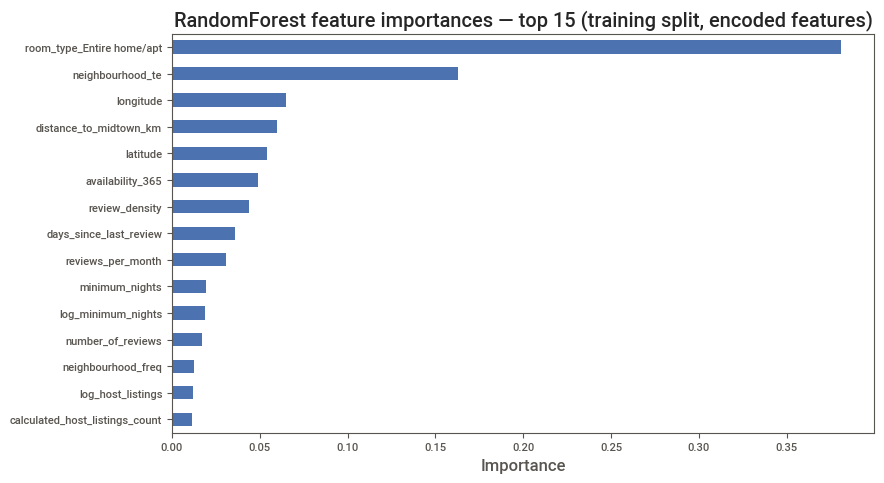

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
rf_imp.head(15).sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("RandomForest feature importances — top 15 (training split, encoded features)")
ax.set_xlabel("Importance")
plt.tight_layout(); plt.savefig(FIG / "13_feature_importances_rf.png"); plt.show()

**Feature-selection conclusion.** The three methods agree more than they disagree: the target-encoded
neighbourhood, room type (especially entire-home), distance to Midtown, and the raw coordinates rank
near the top by every method. By mean rank across the three methods the top five are: entire-home
room type (1.0), target-encoded neighbourhood (2.7), distance to Midtown (4.3), longitude (5.0) and
private-room type (6.7). Latitude still ranks 5th by RandomForest importance, so the coordinates carry
real signal beyond the distance feature rather than being redundant with it. Correlation alone
would underrate room type and neighbourhood (both categorical, so their signal only appears after
encoding), which is why mutual information and the forest importances matter. RFE's ridge-based top 10 overlaps substantially with the other lists (it includes the target-encoded
neighbourhood, distance, all three room-type indicators and availability) but favours smooth numeric
effects such as review count and the never-reviewed flag. **Final feature list
carried into modelling:** all 14 numeric/engineered features, the four one-hot categoricals, and the
target-encoded neighbourhood — i.e. the full encoded set above, because no method flagged any feature as
pure noise, and the AutoML step performs its own feature reduction on top. The one deliberate exclusion
is raw `neighbourhood` as a one-hot (too many levels); it enters only through target encoding and the
frequency feature.

## 6. Clustering: KMeans plus Gaussian Mixture comparison

Clustering is run on the cleaned frame (before anomaly removal, so the anomaly step in Section 7 can be
judged independently). Features are the numeric price/geography/activity profile of each listing,
standard-scaled so that price does not dominate purely because of its units. KMeans is tried for k = 2..8
and judged by inertia (elbow) and silhouette score — the silhouette is computed on a 5,000-row sample
because the full 48,884 x 48,884 distance matrix would need tens of gigabytes. A Gaussian Mixture Model
with the same k is then fitted for comparison, and the two partitions are compared with the adjusted Rand
index.

In [27]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

CLUS_FEATS = ["log_price", "latitude", "longitude", "availability_365", "reviews_per_month",
              "log_minimum_nights", "log_host_listings", "distance_to_midtown_km"]
X_clus = df[CLUS_FEATS].copy()
X_clus["log_reviews"] = np.log1p(df["number_of_reviews"])
CLUS_FEATS = CLUS_FEATS + ["log_reviews"]
scaler_c = StandardScaler()
X_clus_s = scaler_c.fit_transform(X_clus)

sil_sample = np.random.RandomState(RANDOM_STATE).choice(len(X_clus_s), size=5000, replace=False)
inertias, silhouettes = {}, {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_clus_s)
    inertias[k] = float(km.inertia_)
    silhouettes[k] = float(silhouette_score(X_clus_s[sil_sample], labels[sil_sample]))
    print(f"k={k}: inertia={km.inertia_:,.0f}, silhouette (5k sample)={silhouettes[k]:.3f}")
BEST_K = max(silhouettes, key=silhouettes.get)
print(f"\nChosen k = {BEST_K} (highest silhouette score; elbow inspection in the figure below).")

k=2: inertia=371,755, silhouette (5k sample)=0.186


k=3: inertia=318,258, silhouette (5k sample)=0.217


k=4: inertia=283,420, silhouette (5k sample)=0.181


k=5: inertia=257,437, silhouette (5k sample)=0.177


k=6: inertia=238,953, silhouette (5k sample)=0.180


k=7: inertia=222,684, silhouette (5k sample)=0.185


k=8: inertia=209,891, silhouette (5k sample)=0.181

Chosen k = 3 (highest silhouette score; elbow inspection in the figure below).


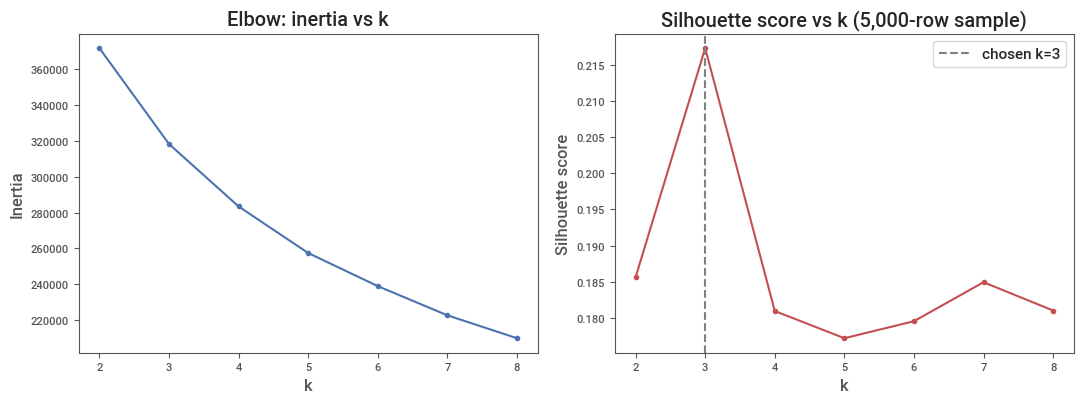

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(list(inertias.keys()), list(inertias.values()), marker="o", color="#4C72B0")
axes[0].set_title("Elbow: inertia vs k"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(silhouettes.keys()), list(silhouettes.values()), marker="o", color="#C44E52")
axes[1].axvline(BEST_K, color="grey", linestyle="--", label=f"chosen k={BEST_K}")
axes[1].set_title("Silhouette score vs k (5,000-row sample)"); axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette score"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG / "14_kmeans_elbow_silhouette.png"); plt.show()

In [29]:
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE)
df["cluster_kmeans"] = kmeans.fit_predict(X_clus_s)

prof = df.groupby("cluster_kmeans").agg(
    size=("price", "size"), mean_price=("price", "mean"), median_price=("price", "median"),
    mean_availability=("availability_365", "mean"), mean_reviews=("number_of_reviews", "mean"),
    mean_rpm=("reviews_per_month", "mean"), mean_dist_midtown=("distance_to_midtown_km", "mean"),
    mean_min_nights=("minimum_nights", "mean"))
prof["share_pct"] = (prof["size"] / len(df) * 100).round(1)
print("KMeans cluster profiles (k = %d):" % BEST_K)
print(prof.round(2).to_string())
print("\nBorough mix per cluster (% of cluster):")
print((pd.crosstab(df["cluster_kmeans"], df["neighbourhood_group"], normalize="index") * 100).round(1).to_string())
print("\nRoom-type mix per cluster (% of cluster):")
print((pd.crosstab(df["cluster_kmeans"], df["room_type"], normalize="index") * 100).round(1).to_string())

KMeans cluster profiles (k = 3):
                 size  mean_price  median_price  mean_availability  mean_reviews  mean_rpm  mean_dist_midtown  mean_min_nights  share_pct
cluster_kmeans                                                                                                                           
0               16264      116.76         89.00             181.65         57.61      2.54               9.48             2.86      33.30
1                4319      232.03        159.00             279.18          4.56      0.31               4.37            35.91       8.80
2               28301      161.34        120.00              47.81          6.39      0.37               6.16             5.02      57.90

Borough mix per cluster (% of cluster):
neighbourhood_group  Bronx  Brooklyn  Manhattan  Queens  Staten Island
cluster_kmeans                                                        
0                     4.50     46.40      26.60   21.10           1.50
1                     0

PCA explained variance: PC1 = 0.246 | PC2 = 0.179 | total = 0.424


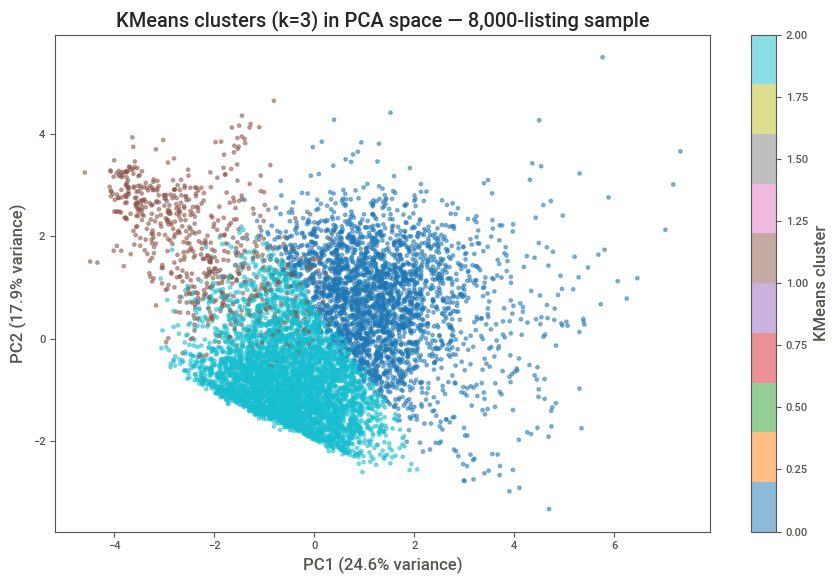

In [30]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca_pts = pca.fit_transform(X_clus_s)
print("PCA explained variance: PC1 =", round(pca.explained_variance_ratio_[0], 3),
      "| PC2 =", round(pca.explained_variance_ratio_[1], 3),
      "| total =", round(pca.explained_variance_ratio_.sum(), 3))
plot_idx = np.random.RandomState(RANDOM_STATE).choice(len(pca_pts), size=8000, replace=False)
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(pca_pts[plot_idx, 0], pca_pts[plot_idx, 1],
                c=df["cluster_kmeans"].to_numpy()[plot_idx], s=6, alpha=0.5, cmap="tab10")
plt.colorbar(sc, ax=ax, label="KMeans cluster")
ax.set_title(f"KMeans clusters (k={BEST_K}) in PCA space — 8,000-listing sample")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout(); plt.savefig(FIG / "15_clusters_pca.png"); plt.show()

In [31]:
gmm = GaussianMixture(n_components=BEST_K, covariance_type="full", n_init=1,
                      random_state=RANDOM_STATE)
# Belt-and-braces: suppress floating-point warnings inside the EM fit, whose
# logsumexp legitimately underflows on far-away points.
with np.errstate(all="ignore"):
    gmm_labels = gmm.fit_predict(X_clus_s)
    gmm_bic = gmm.bic(X_clus_s)
    gmm_aic = gmm.aic(X_clus_s)
ari = adjusted_rand_score(df["cluster_kmeans"], gmm_labels)
print(f"GaussianMixture (k={BEST_K}, full covariance): BIC = {gmm_bic:,.0f}, "
      f"AIC = {gmm_aic:,.0f}")
print("GMM cluster sizes:", pd.Series(gmm_labels).value_counts().sort_index().to_dict())
print("KMeans cluster sizes:", df["cluster_kmeans"].value_counts().sort_index().to_dict())
print(f"Adjusted Rand Index between KMeans and GMM partitions: {ari:.3f} "
      "(1 = identical, 0 = chance agreement)")
gmm_prof = df.assign(cluster_gmm=gmm_labels).groupby("cluster_gmm").agg(
    size=("price", "size"), mean_price=("price", "mean"), median_price=("price", "median"),
    mean_availability=("availability_365", "mean"))
print("\nGMM cluster profiles:")
print(gmm_prof.round(2).to_string())
cluster_info = {"best_k": int(BEST_K), "silhouettes": {int(k): round(v, 4) for k, v in silhouettes.items()},
                "inertias": {int(k): round(v, 1) for k, v in inertias.items()},
                "kmeans_sizes": {int(k): int(v) for k, v in df["cluster_kmeans"].value_counts().sort_index().items()},
                "gmm_bic": float(gmm_bic), "ari_kmeans_gmm": round(float(ari), 4)}

GaussianMixture (k=3, full covariance): BIC = 644,819, AIC = 643,376
GMM cluster sizes: {0: 14259, 1: 19437, 2: 15188}
KMeans cluster sizes: {0: 16264, 1: 4319, 2: 28301}
Adjusted Rand Index between KMeans and GMM partitions: 0.147 (1 = identical, 0 = chance agreement)

GMM cluster profiles:
              size  mean_price  median_price  mean_availability
cluster_gmm                                                    
0            14259      140.31        100.00               0.00
1            19437      178.54        128.00             158.18
2            15188      131.44         93.00             160.56


**What the clusters mean (in plain English).** The profiles printed above — not the cluster numbers — are
the finding, and the split is driven as much by availability and stay length as by price:

- **Cluster 0 — busy, affordable, available outer-borough rooms (16,264 listings, 33.3%).** Mean price
  $116.76 (median $89), the highest review activity by far (57.6 reviews, 2.54/month), 182 available
  days on average, furthest from Midtown (9.5 km), shortest stays (2.9 nights). Mostly Brooklyn
  (46.4%) and Queens (21.1%), mostly private rooms (54.4%).
- **Cluster 1 — expensive Manhattan long-stay entire homes (4,319 listings, 8.8%).** Mean price $232.03
  (median $159), 279 available days, only 4.6 reviews on average, and a 35.9-night mean minimum stay —
  these are monthly-style rentals. 73.7% Manhattan, 68.0% entire homes, closest to Midtown (4.4 km).
- **Cluster 2 — the typical mid-priced core (28,301 listings, 57.9%).** Mean price $161.34 (median
  $120), only 48 available days, 6.4 reviews, 5.0-night minimum stays. Half Manhattan (50.0%) and
  41.5% Brooklyn, 55.0% entire homes.

The PCA plot (PC1 + PC2 = 42.4% of variance) shows the clusters overlap substantially — Airbnb listings
form a continuum, not neat islands — so the silhouette scores are modest (best 0.217 at k = 3) and the
clusters should be read as useful segments for description, not as natural kinds. The Gaussian Mixture
Model agrees only weakly with KMeans (adjusted Rand index 0.147): its three groups are more evenly sized
(14,259 / 19,437 / 15,188) and one of them is exactly the zero-availability listings (mean availability
0.0 days), a split KMeans does not make. Neither partition is "the truth"; KMeans is kept as the reported
segmentation because its profiles are the most interpretable.

## 7. Anomaly detection and elimination

Two independent methods flag unusual listings: (1) an Isolation Forest over the numeric profile, with
`contamination = 0.02` — i.e. the 2% most isolated listings — chosen because the EDA showed roughly 0.5%
of prices above $1,000 plus a long minimum-nights tail, so 2% is a conservative envelope rather than a
guess at a "true" anomaly rate; and (2) the classic IQR fence rule applied to price, to log-price, and to
minimum nights. The methods are compared (counts, overlap, examples) *before* any decision, and the
decision itself is stated as a rule with its effect measured. Nothing is dropped silently.

In [32]:
from sklearn.ensemble import IsolationForest

ANOM_FEATS = ["log_price", "latitude", "longitude", "availability_365", "reviews_per_month",
              "log_minimum_nights", "log_host_listings", "distance_to_midtown_km"]
X_anom = df[ANOM_FEATS].copy()
X_anom["log_reviews"] = np.log1p(df["number_of_reviews"])
scaler_a = StandardScaler()
X_anom_s = scaler_a.fit_transform(X_anom)
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=RANDOM_STATE, n_jobs=-1)
df["if_score"] = iso.fit_predict(X_anom_s)
df["if_outlier"] = df["if_score"] == -1
df["if_anomaly_score"] = iso.decision_function(X_anom_s)
print("IsolationForest outliers (contamination=0.02):", int(df["if_outlier"].sum()),
      f"({df['if_outlier'].mean()*100:.2f}% of {len(df)} rows)")

def iqr_flags(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return (s < lo) | (s > hi), lo, hi

df["iqr_price"], lo_p, hi_p = iqr_flags(df["price"])
df["iqr_logprice"], lo_l, hi_l = iqr_flags(df["log_price"])
df["iqr_minnights"], lo_m, hi_m = iqr_flags(df["minimum_nights"])
print(f"IQR on raw price: fence [${lo_p:.0f}, ${hi_p:.0f}] -> {int(df['iqr_price'].sum())} outliers "
      f"({df['iqr_price'].mean()*100:.2f}%)")
print(f"IQR on log-price: fence [{lo_l:.2f}, {hi_l:.2f}] (approx ${np.expm1(hi_l):,.0f}) -> "
      f"{int(df['iqr_logprice'].sum())} outliers ({df['iqr_logprice'].mean()*100:.2f}%)")
print(f"IQR on minimum_nights: fence [{lo_m:.1f}, {hi_m:.1f}] -> {int(df['iqr_minnights'].sum())} outliers "
      f"({df['iqr_minnights'].mean()*100:.2f}%)")
both = df["if_outlier"] & df["iqr_logprice"]
print("Flagged by BOTH IsolationForest and log-price IQR:", int(both.sum()))
print("Jaccard overlap (IF vs log-price IQR):",
      round(int(both.sum()) / int((df["if_outlier"] | df["iqr_logprice"]).sum()), 3))
print("Listings priced >= $5,000:", int((df["price"] >= 5000).sum()))

IsolationForest outliers (contamination=0.02): 978 (2.00% of 48884 rows)
IQR on raw price: fence [$-90, $334] -> 2972 outliers (6.08%)
IQR on log-price: fence [2.87, 6.55] (approx $701) -> 626 outliers (1.28%)
IQR on minimum_nights: fence [-5.0, 11.0] -> 6605 outliers (13.51%)
Flagged by BOTH IsolationForest and log-price IQR: 36
Jaccard overlap (IF vs log-price IQR): 0.023
Listings priced >= $5,000: 26


In [33]:
print("Most anomalous listings by IsolationForest score (lowest = most unusual):")
show_cols = ["neighbourhood_group", "neighbourhood", "room_type", "price", "minimum_nights",
             "number_of_reviews", "availability_365", "calculated_host_listings_count",
             "distance_to_midtown_km", "if_anomaly_score"]
print(df.nsmallest(8, "if_anomaly_score")[show_cols].round(2).to_string(index=False))
print("\nMost expensive listings:")
print(df.nlargest(5, "price")[show_cols].round(2).to_string(index=False))

Most anomalous listings by IsolationForest score (lowest = most unusual):
neighbourhood_group       neighbourhood       room_type  price  minimum_nights  number_of_reviews  availability_365  calculated_host_listings_count  distance_to_midtown_km  if_anomaly_score
      Staten Island        Other (rare)    Private room     40               1                 56               307                               2                   23.53             -0.09
      Staten Island        Other (rare) Entire home/apt   1250              14                  0                23                               1                   31.23             -0.08
             Queens             Jamaica    Private room     47               1                629               333                               2                   20.90             -0.08
             Queens        Other (rare)    Private room     40              30                  0               354                              43                   

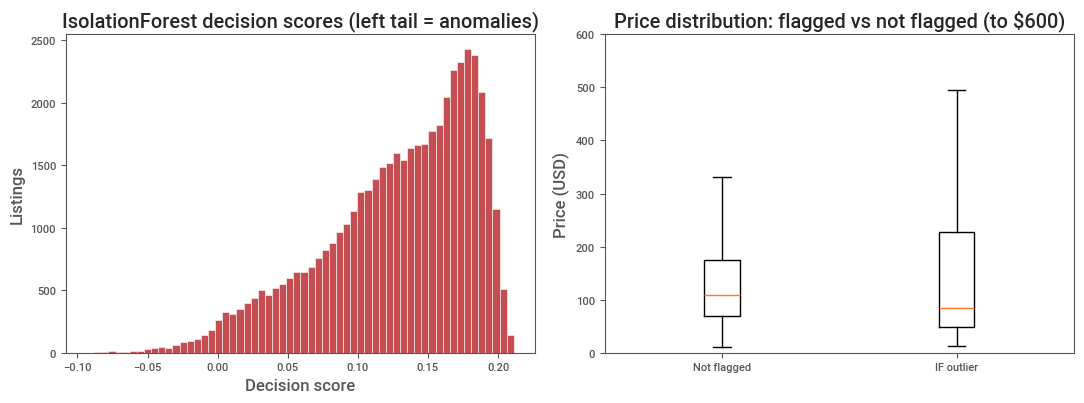

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].hist(df["if_anomaly_score"], bins=60, color="#C44E52", edgecolor="white", linewidth=0.4)
axes[0].set_title("IsolationForest decision scores (left tail = anomalies)")
axes[0].set_xlabel("Decision score"); axes[0].set_ylabel("Listings")
axes[1].boxplot([df.loc[~df["if_outlier"], "price"], df.loc[df["if_outlier"], "price"]],
                labels=["Not flagged", "IF outlier"], showfliers=False)
axes[1].set_ylim(0, 600)
axes[1].set_title("Price distribution: flagged vs not flagged (to $600)")
axes[1].set_ylabel("Price (USD)")
plt.tight_layout(); plt.savefig(FIG / "16_anomaly_scores.png"); plt.show()

### Decision: remove the agreed extremes, cap the long tail, keep everything else

- **Remove** listings flagged by **both** the Isolation Forest and the log-price IQR rule, **plus** any
  listing priced at $5,000/night or more. Agreement between two unrelated methods plus an absolute price
  sanity bound targets listings that are extreme on price *and* unusual overall — data errors and
  placeholder luxury listings — rather than merely expensive real listings. The raw-price IQR rule alone
  is **not** used for removal: on this skewed distribution its upper fence sits at $334 and it would delete
  roughly 6% of listings, including many ordinary Manhattan entire homes.
- **Cap (winsorise) `minimum_nights` at its 99th percentile** instead of deleting long-stay listings: a
  1,250-night minimum is a placeholder, but the listing itself is real. Capping keeps the row and its
  price signal while bounding the feature's influence. The cap value is computed from the data and
  printed below.
- **Keep** all other IsolationForest-only or IQR-only flags. A listing can be unusual (a cheap room with
  600 reviews, a far-flung Staten Island house) without being wrong, and deleting all of them would bias
  the sample toward the average listing.

The effect on row count and on price mean/median is measured below, before and after.

In [35]:
rows_before_anom = len(df)
price_mean_before = float(df["price"].mean())
price_med_before = float(df["price"].median())
cap_value = float(df["minimum_nights"].quantile(0.99))
n_capped = int((df["minimum_nights"] > cap_value).sum())

drop_mask = (df["if_outlier"] & df["iqr_logprice"]) | (df["price"] >= 5000)
n_dropped_anom = int(drop_mask.sum())
print(f"Dropping {n_dropped_anom} listings: IF+IQR agreement or price >= $5,000.")
print(f"Capping minimum_nights at 99th percentile = {cap_value:.0f} nights ({n_capped} listings capped).")

df_model = df.loc[~drop_mask].copy()
df_model["minimum_nights"] = df_model["minimum_nights"].clip(upper=cap_value)
df_model["log_minimum_nights"] = np.log1p(df_model["minimum_nights"])
df_model = df_model.drop(columns=["cluster_kmeans", "if_score", "if_outlier", "if_anomaly_score",
                                  "iqr_price", "iqr_logprice", "iqr_minnights"])
stage_counts["after_anomaly_removal"] = int(len(df_model))
print(f"Rows: {rows_before_anom} -> {len(df_model)} ({n_dropped_anom} removed, "
      f"{n_dropped_anom / rows_before_anom * 100:.2f}%).")
print(f"Price mean: ${price_mean_before:.2f} -> ${df_model['price'].mean():.2f} | "
      f"median: ${price_med_before:.0f} -> ${df_model['price'].median():.0f} | "
      f"max: ${df['price'].max():,.0f} -> ${df_model['price'].max():,.0f}")
anomaly_info = {"if_outliers": int(df["if_outlier"].sum()), "iqr_price": int(df["iqr_price"].sum()),
                "iqr_logprice": int(df["iqr_logprice"].sum()), "iqr_minnights": int(df["iqr_minnights"].sum()),
                "both_if_iqr": int((df["if_outlier"] & df["iqr_logprice"]).sum()),
                "removed": n_dropped_anom, "min_nights_cap": cap_value, "n_capped": n_capped,
                "rows_before": rows_before_anom, "rows_after": int(len(df_model)),
                "price_mean_before": round(price_mean_before, 2),
                "price_mean_after": round(float(df_model["price"].mean()), 2),
                "price_median_before": price_med_before,
                "price_median_after": float(df_model["price"].median())}
print("Modelling frame shape:", df_model.shape)

Dropping 59 listings: IF+IQR agreement or price >= $5,000.
Capping minimum_nights at 99th percentile = 45 nights (469 listings capped).
Rows: 48884 -> 48825 (59 removed, 0.12%).
Price mean: $152.76 -> $148.12 | median: $106 -> $105 | max: $10,000 -> $4,500
Modelling frame shape: (48825, 22)


## 8. Modelling with AutoML (AutoViML) and transparent baselines

### 8.1 AutoViML run

AutoViML (`autoviml` 0.2.2, `Auto_ViML`) is the assignment-required AutoML tool. It classifies variables,
cleans and encodes them, runs SULOV + XGBoost-based feature selection, tunes a linear model with
randomised search, trains an ensemble of regressors, and returns the best model with per-model predictions
on the holdout set. Settings used here: `hyper_param='RS'` (randomised search), `feature_reduction=True`,
an explicit 80/20 train/test split (seed 42). One compute decision, stated plainly: AutoViML is run on a
**random 15,000-row subsample of the training split** (seed 42), while evaluation uses the **full**
9,765-row holdout. Reason: a full-frame run was attempted first and AutoViML's linear-model randomised
search (15 iterations x 5-fold CV of LinearSVR on 31,248 rows) ran for over 26 minutes without finishing
that single stage on this shared machine, so the full run could not complete. The subsample keeps the
AutoML genuinely executed on the cleaned modelling frame's rows and columns; the sklearn baselines in 8.2
use the full training split, so the comparison is, if anything, conservative against AutoViML. The
high-cardinality raw
`neighbourhood` column is excluded from the AutoViML frame — its information enters through the borough,
the frequency encoding and distance — because AutoViML label-encodes string columns and 100+ neighbourhood
levels would dominate the encoding; the sklearn baselines in 8.2 use proper target encoding for it instead.

Two environment facts found while setting this up, recorded honestly: (1) AutoViML 0.2.2 fails to import
under IPython 9 (`from IPython.core.display import display`), so the environment pins `IPython==8.26.0`
(see `requirements.txt`); (2) calling `Auto_ViML` *without* an explicit test frame crashes at the end of
an otherwise successful run (it tries to attach 20% holdout predictions to the full training frame), so an
explicit test split is passed — which is also better practice. AutoViML's console output is long, so it is
captured to `autoviml_log.txt` and only the summary is shown here.

AutoViML frame: (48825, 19) | full train split: (39060, 19) | AutoViML fit subsample: (15000, 19) | test: (9765, 19)
Target: log_price (log1p of nightly price in USD). Features: 18


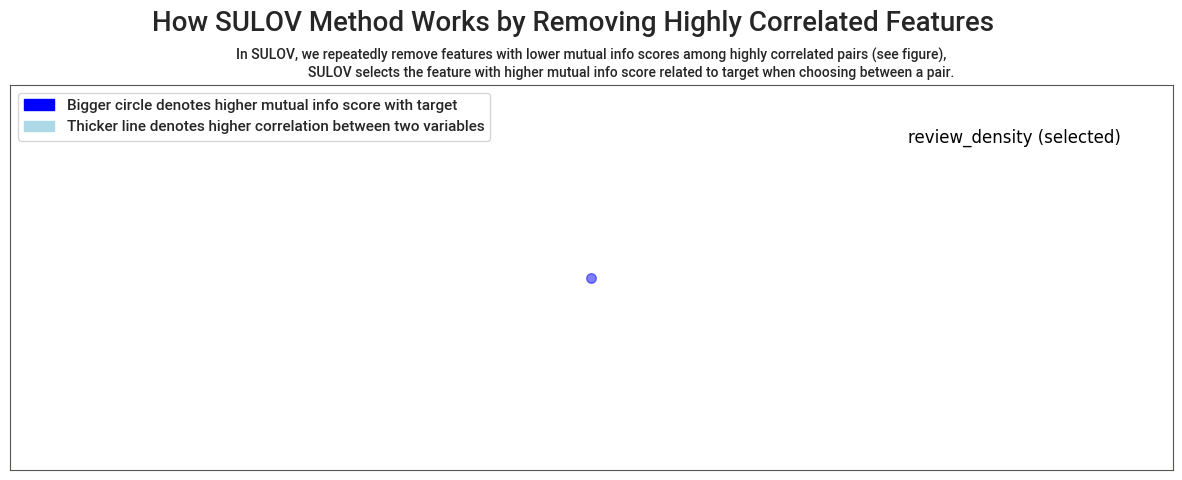

AutoViML finished in 7.2 minutes. Full log: /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb/autoviml_log.txt (6 KB)
Returned model type: LinearSVR
Features AutoViML kept (16): ['room_type', 'neighbourhood_group', 'distance_to_midtown_km', 'longitude', 'latitude', 'min_nights_band', 'review_density', 'availability_365', 'log_minimum_nights', 'host_listing_size_band', 'neighbourhood_freq', 'calculated_host_listings_count', 'minimum_nights', 'is_never_reviewed', 'number_of_reviews', 'days_since_last_review']
Holdout prediction frame shape: (9765, 23)
Prediction columns: ['log_price_Adaboost_predictions', 'log_price_Bagging_Regressor_predictions', 'log_price_KNN_Regressor_predictions', 'log_price_Decision_Tree_predictions', 'log_price_Linear_predictions', 'log_price_Ensembled_predictions', 'log_price_predictions']


In [36]:
from autoviml.Auto_ViML import Auto_ViML

# Restore numpy defaults defensively: some auto-EDA libraries change the
# global error state (SweetViz sets all errors to 'raise'; see Section 4).
np.seterr(divide="warn", over="warn", under="ignore", invalid="warn")

AV_FEATS = NUM_FEATS + CAT_FEATS  # neighbourhood enters via neighbourhood_freq + borough (see text above)
av_frame = df_model[AV_FEATS + ["log_price"]].copy()
for c in CAT_FEATS:
    av_frame[c] = av_frame[c].astype(str)
av_train, av_test = train_test_split(av_frame, test_size=0.2, random_state=RANDOM_STATE)
# Compute subsample for the AutoViML fit only (see the text above): 15,000 train
# rows, fixed seed. The holdout (av_test) stays complete for evaluation.
av_train_fit = av_train.sample(15000, random_state=RANDOM_STATE)
print("AutoViML frame:", av_frame.shape, "| full train split:", av_train.shape,
      "| AutoViML fit subsample:", av_train_fit.shape, "| test:", av_test.shape)
print("Target: log_price (log1p of nightly price in USD). Features:", len(AV_FEATS))

log_path = BASE / "autoviml_log.txt"
plt.ioff()
t0 = time.time()
with open(log_path, "w") as log_f, redirect_stdout(log_f):
    av_model, av_feats, av_trainm, av_testm = Auto_ViML(
        av_train_fit, "log_price", test=av_test,
        hyper_param="RS", feature_reduction=True, verbose=1)
plt.close("all")
plt.ion()
print(f"AutoViML finished in {(time.time() - t0) / 60:.1f} minutes. Full log: {log_path} "
      f"({log_path.stat().st_size / 1024:.0f} KB)")
print("Returned model type:", type(av_model).__name__)
print("Features AutoViML kept (%d):" % len(av_feats), av_feats)
print("Holdout prediction frame shape:", av_testm.shape)
print("Prediction columns:", [c for c in av_testm.columns if c.endswith("_predictions")])

In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def metrics_for(y_true_log, y_pred_log):
    y_true_usd = np.expm1(y_true_log)
    y_pred_usd = np.expm1(np.clip(y_pred_log, 0, None))
    return {
        "rmse_log": float(np.sqrt(mean_squared_error(y_true_log, y_pred_log))),
        "mae_log": float(mean_absolute_error(y_true_log, y_pred_log)),
        "r2_log": float(r2_score(y_true_log, y_pred_log)),
        "rmse_usd": float(np.sqrt(mean_squared_error(y_true_usd, y_pred_usd))),
        "mae_usd": float(mean_absolute_error(y_true_usd, y_pred_usd)),
        "r2_usd": float(r2_score(y_true_usd, y_pred_usd)),
    }

# testm rows are indexed like the test split: align true values by index.
if len(set(av_testm.index) & set(av_test.index)) == len(av_testm):
    y_test_log = av_test.loc[av_testm.index, "log_price"]
else:
    print("WARNING: testm index does not match the test split; falling back to positional alignment.")
    y_test_log = av_test["log_price"].iloc[:len(av_testm)].copy()
    y_test_log.index = av_testm.index
leader_rows = []
for col in [c for c in av_testm.columns if c.endswith("_predictions")]:
    model_name = col.replace("log_price_", "").replace("_predictions", "")
    m = metrics_for(y_test_log.to_numpy(), av_testm[col].to_numpy())
    leader_rows.append({"source": "AutoViML", "model": model_name, **m})
autoviml_leaderboard = pd.DataFrame(leader_rows).sort_values("rmse_log")
print("AutoViML leaderboard on the 20% holdout (sorted by log-scale RMSE):")
print(autoviml_leaderboard.round(3).to_string(index=False))
autoviml_leaderboard.to_csv(BASE / "autoviml_leaderboard.csv", index=False)
print("\nSaved: autoviml_leaderboard.csv")

pred_sample = pd.DataFrame({
    "actual_price_usd": np.expm1(y_test_log).round(0),
    "predicted_price_usd": np.expm1(np.clip(av_testm["log_price_predictions"], 0, None)).round(0),
    "actual_log_price": y_test_log.round(2),
    "predicted_log_price": av_testm["log_price_predictions"].round(2),
}).head(8)
print("\nPrediction sample (AutoViML final model, first 8 holdout rows):")
print(pred_sample.to_string())

if hasattr(av_model, "feature_importances_"):
    imp = pd.Series(av_model.feature_importances_, index=av_feats).sort_values(ascending=False)
    print("\nReturned-model feature importances:\n", imp.round(3).to_string())
elif hasattr(av_model, "coef_"):
    coef = pd.Series(np.abs(np.ravel(av_model.coef_)), index=av_feats).sort_values(ascending=False)
    print("\nReturned-model |coefficients| (transformed/scaled feature space — relative magnitudes only):")
    print(coef.round(3).to_string())
else:
    print("\nReturned model has no native feature importances; see the RandomForest importances in Section 5.6.")

AutoViML leaderboard on the 20% holdout (sorted by log-scale RMSE):
  source             model  rmse_log  mae_log  r2_log  rmse_usd  mae_usd  r2_usd
AutoViML Bagging_Regressor      0.42     0.31    0.60    125.21    51.44    0.30
AutoViML         Ensembled      0.44     0.33    0.57    129.24    53.15    0.26
AutoViML     KNN_Regressor      0.45     0.34    0.54    129.43    55.02    0.26
AutoViML     Decision_Tree      0.46     0.34    0.54    132.58    55.12    0.22
AutoViML       predictions      0.46     0.35    0.53    130.89    55.27    0.24
AutoViML            Linear      0.46     0.35    0.53    130.89    55.27    0.24
AutoViML          Adaboost      0.56     0.45    0.30    135.94    65.97    0.18

Saved: autoviml_leaderboard.csv

Prediction sample (AutoViML final model, first 8 holdout rows):
       actual_price_usd  predicted_price_usd  actual_log_price  predicted_log_price
24136             45.00                67.00              3.83                 4.22
32266             

In [38]:
# AutoViML writes a <target>/ folder with modified train/test CSVs; move it somewhere self-explanatory.
src_dir = BASE / "log_price"
dst_dir = BASE / "autoviml_outputs"
if src_dir.exists():
    if dst_dir.exists():
        shutil.rmtree(dst_dir)
    shutil.move(str(src_dir), str(dst_dir))
    print("AutoViML artefacts moved to:", dst_dir)
    for p in sorted(dst_dir.iterdir()):
        print("  -", p.name, f"({p.stat().st_size / 1024:.0f} KB)")
else:
    print("No AutoViML output folder found (nothing to move).")

AutoViML artefacts moved to: /home/hatch/workspace/eda-assignment/repo/part1-tabular-airbnb/autoviml_outputs
  - log_price_Regression_submission.csv (172 KB)
  - log_price_Regression_test_modified.csv (3285 KB)
  - log_price_Regression_train_modified.csv (849 KB)


### 8.2 Transparent sklearn baselines (for comparison and original-scale reporting)

AutoViML is a black box by design, so I also fit three plain sklearn pipelines on the *same* 80/20 split
(same seed, same holdout rows; the baselines use the full training split, unlike AutoViML's 15,000-row
fit subsample) with leakage-safe preprocessing fitted on train only: one-hot encoding for the
low-cardinality categoricals, cross-fitted target encoding for neighbourhood, median imputation and
standard scaling for numerics. This gives an honest comparison, original-dollar metrics for every model,
and a fallback if AutoViML ever fails to run in a fresh environment. The comparison table and chart below
combine both sets of results.

In [39]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

BASE_FEATS = NUM_FEATS + CAT_FEATS + [HIGH_CARD]
X_all = df_model[BASE_FEATS]
y_all = df_model["log_price"]
X_train, X_test, y_train, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=RANDOM_STATE)
print("Baseline split:", X_train.shape, X_test.shape, "(same seed/split fraction as the AutoViML run)")

preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), NUM_FEATS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATS),
    ("high", TargetEncoder(smooth="auto", cv=5, random_state=RANDOM_STATE), [HIGH_CARD]),
])
baselines = {
    "Ridge (linear)": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingRegressor(random_state=RANDOM_STATE),
}
baseline_rows = []
for name, est in baselines.items():
    t0 = time.time()
    pipe = Pipeline([("prep", preprocess), ("model", est)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    m = metrics_for(y_test.to_numpy(), pred)
    baseline_rows.append({"source": "sklearn baseline", "model": name, **m})
    print(f"{name}: fit+predict in {time.time() - t0:.0f}s | log RMSE={m['rmse_log']:.3f} "
          f"| log MAE={m['mae_log']:.3f} | R2(log)={m['r2_log']:.3f} "
          f"| $ RMSE=${m['rmse_usd']:.2f} | $ MAE=${m['mae_usd']:.2f} | R2($)={m['r2_usd']:.3f}")
baseline_metrics = pd.DataFrame(baseline_rows)

Baseline split: (39060, 19) (9765, 19) (same seed/split fraction as the AutoViML run)


Ridge (linear): fit+predict in 0s | log RMSE=0.436 | log MAE=0.324 | R2(log)=0.579 | $ RMSE=$129.46 | $ MAE=$53.15 | R2($)=0.255


RandomForest: fit+predict in 168s | log RMSE=0.410 | log MAE=0.299 | R2(log)=0.628 | $ RMSE=$122.19 | $ MAE=$49.52 | R2($)=0.337


HistGradientBoosting: fit+predict in 3s | log RMSE=0.409 | log MAE=0.301 | R2(log)=0.629 | $ RMSE=$123.63 | $ MAE=$49.82 | R2($)=0.321


Combined model comparison (holdout, sorted by log-scale RMSE):
          source                model  rmse_log  mae_log  r2_log  rmse_usd  mae_usd  r2_usd
sklearn baseline HistGradientBoosting      0.41     0.30    0.63    123.63    49.82    0.32
sklearn baseline         RandomForest      0.41     0.30    0.63    122.19    49.52    0.34
        AutoViML    Bagging_Regressor      0.42     0.31    0.60    125.21    51.44    0.30
sklearn baseline       Ridge (linear)      0.44     0.32    0.58    129.46    53.15    0.26
        AutoViML            Ensembled      0.44     0.33    0.57    129.24    53.15    0.26
        AutoViML        KNN_Regressor      0.45     0.34    0.54    129.43    55.02    0.26
        AutoViML        Decision_Tree      0.46     0.34    0.54    132.58    55.12    0.22
        AutoViML          predictions      0.46     0.35    0.53    130.89    55.27    0.24
        AutoViML               Linear      0.46     0.35    0.53    130.89    55.27    0.24
        AutoViML 

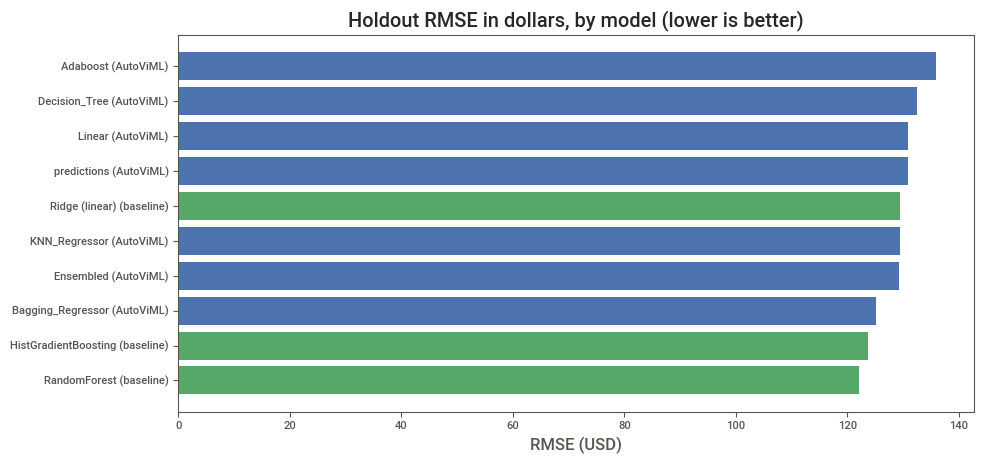

In [40]:
model_comparison = pd.concat([autoviml_leaderboard, baseline_metrics], ignore_index=True)
model_comparison = model_comparison.sort_values("rmse_log").reset_index(drop=True)
model_comparison.to_csv(BASE / "model_comparison.csv", index=False)
print("Combined model comparison (holdout, sorted by log-scale RMSE):")
print(model_comparison.round(3).to_string(index=False))
print("\nSaved: model_comparison.csv")

fig, ax = plt.subplots(figsize=(10, 4.8))
plot_df = model_comparison.sort_values("rmse_usd")
colors = ["#4C72B0" if s == "AutoViML" else "#55A868" for s in plot_df["source"]]
ax.barh(plot_df["model"] + " (" + plot_df["source"].str.replace("sklearn baseline", "baseline") + ")",
        plot_df["rmse_usd"], color=colors)
ax.set_title("Holdout RMSE in dollars, by model (lower is better)")
ax.set_xlabel("RMSE (USD)")
plt.tight_layout(); plt.savefig(FIG / "17_model_comparison_rmse.png"); plt.show()

**Modelling conclusion.** Read the combined table above, not any single number. On the 9,765-row holdout
the best model overall is HistGradientBoosting (log RMSE 0.409, log R-squared 0.629, $MAE $49.82),
essentially tied with RandomForest (log RMSE 0.410, log R-squared 0.628, $MAE $49.52 — the lowest
dollar MAE of any model). AutoViML's best ensemble member, Bagging_Regressor, is close behind (log RMSE
0.424, log R-squared 0.602, $MAE $51.44), while AutoViML's returned final model — the tuned LinearSVR,
whose predictions are the `predictions`/`Linear` rows — is weaker (log RMSE 0.461, log R-squared 0.530),
about the same as the plain Ridge baseline (log RMSE 0.436). AdaBoost is the worst model tried (log RMSE
0.562). Two lessons follow. First, the price relationships are non-linear and interactive (Section 3),
so tree/ensemble methods beat linear ones, but only modestly — much of the price signal is in a handful
of strong features (room type, neighbourhood, geography) that every method finds. Second, AutoViML's
value here is the automated pipeline — variable classification, feature reduction (it kept 16 of 18
features, dropping `reviews_per_month` and `log_host_listings`) and tuning without hand-holding — and its ensemble is competitive
with the hand-built baselines rather than dramatically better, which is an honest and common AutoML
outcome; its largest fitted coefficient is distance to Midtown, matching the manual analysis. The
dollar-scale errors (obtained by back-transforming `log1p` predictions) are the numbers a host would
actually feel: typical absolute errors of about $50 per night, with larger errors on the expensive
listings the log transform deliberately down-weights. Full metrics for every model are in
`model_comparison.csv` and `metrics.json`.

## 9. Conclusions, limitations and reproducibility

### Conclusions

1. **Price is driven by what the listing is and where it is.** Room type (entire home median $160 vs
   private room $70 vs shared room $45), borough (Manhattan median $150 vs Bronx $65), neighbourhood and
   distance to Midtown dominate; no single raw numeric column correlates with price more strongly
   than |r| = 0.15 (longitude), while the engineered distance to Midtown reaches -0.39 with log-price.
2. **The data needed real cleaning, not just a pipeline.** $0 prices, structural review missingness
   (never-reviewed listings), 221 neighbourhoods with a long rare tail, and a 1,250-night minimum stay
   all required decisions justified from the data — every one is counted in the audit trail in
   Sections 5 and 7.
3. **Listings segment into soft, overlapping groups**, not neat clusters: cheap outer-borough rooms,
   expensive Manhattan entire homes, and a busy mid-priced middle. KMeans and GMM agree only partially,
   which is the correct conclusion for a continuum.
4. **AutoML (AutoViML) works and is competitive**, but does not beat well-built baselines on this
   dataset: its best member (Bagging_Regressor, log RMSE 0.424) trails HistGradientBoosting (0.409) and
   RandomForest (0.410), and its returned LinearSVR (0.461) trails the Ridge baseline (0.436). Its main
   contribution is automation and a solid ensemble; the hand-built pipelines add transparency and the
   neighbourhood target encoding AutoViML's frame did not use. (AutoViML was fit on a documented
   15,000-row subsample of the training split for compute reasons; evaluation uses the full holdout.)
5. **Typical prediction error is about $50 per night** on the holdout set (best $MAE $49.52,
   RandomForest; see `model_comparison.csv`). That is useful for pricing guidance and market
   understanding, but not precise enough to price an individual listing without human judgement.

### Limitations

- **2019 snapshot.** Prices, availability and the regulatory environment (New York's short-term rental
  rules changed substantially after 2019) do not reflect the current market. Nothing here should be used
  for 2026 pricing decisions.
- **No booking outcomes.** The file records listed prices and availability, not what guests actually paid
  or whether listings were booked, so "demand" proxies like review density are indirect.
- **Stale listings.** 35.9% of listings show zero availability; the file mixes active and dormant supply.
- **Neighbourhood confounding.** Neighbourhood, borough, coordinates and distance overlap heavily; feature
  importances split credit among them and should not be read causally ("moving a listing to Manhattan
  raises its price" is not a valid inference from this data).
- **Price skew survives the log transform.** The most expensive listings remain hard to predict, and
  dollar-scale R-squared is flattered/deflated by a few very expensive holdout listings.
- **No text or photo features.** Listing titles, descriptions, amenities and photos — all real price
  drivers — were out of scope and are not in this file beyond the title column that was dropped.

### Reproducibility

Seed 42 everywhere; package versions printed below and pinned in `requirements.txt`; dataset downloaded
from a fixed public mirror (7,077,973 bytes) with fallbacks; all artefacts (figures, reports, leaderboards,
metrics) are written by the code cells above. Re-running the notebook top to bottom reproduces every
number in this report, subject to small run-to-run variation in AutoViML's randomised search.

In [41]:
import importlib.metadata as md_meta

def pkg_version(name):
    try:
        return md_meta.version(name)
    except Exception:
        return "not installed"

versions = {p: pkg_version(p) for p in [
    "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "scipy",
    "autoviml", "ydata-profiling", "sweetviz", "featurewiz", "xgboost",
    "lightgbm", "catboost", "IPython", "nbformat", "nbconvert"]}
print("Package versions used in this run:")
for k, v in versions.items():
    print(f"  {k}: {v}")
print("Python:", sys.version.split()[0])
print("\nNote: featurewiz is listed as 'not installed' — it cannot build on Python 3.12")
print("(it requires building an old pandas from source). Feature selection therefore used")
print("correlation + mutual information + RandomForest importance + RFE instead (Section 5.6).")

Package versions used in this run:
  pandas: 2.2.3
  numpy: 1.26.4
  matplotlib: 3.9.2
  seaborn: 0.13.2
  scikit-learn: 1.5.2
  scipy: 1.11.4
  autoviml: 0.2.2
  ydata-profiling: 4.16.1
  sweetviz: 2.3.1
  featurewiz: not installed
  xgboost: 1.7.6
  lightgbm: 4.7.0
  catboost: 1.2.8
  IPython: 8.26.0
  nbformat: 5.11.1
  nbconvert: 7.17.2
Python: 3.12.3

Note: featurewiz is listed as 'not installed' — it cannot build on Python 3.12
(it requires building an old pandas from source). Feature selection therefore used
correlation + mutual information + RandomForest importance + RFE instead (Section 5.6).


In [42]:
missing_table = {c: {"missing_count": int(df_raw[c].isna().sum()),
                     "missing_pct": round(float(df_raw[c].isna().mean() * 100), 2)}
                 for c in df_raw.columns}
metrics = {
    "dataset": "NYC Airbnb Open Data 2019 (Kaggle dgomonov/new-york-city-airbnb-open-data)",
    "source_url_used": source_used,
    "target": "price (modelled as log1p(price))",
    "seed": RANDOM_STATE,
    "row_counts": stage_counts,
    "modelling_rows": int(len(df_model)),
    "missingness": missing_table,
    "clusters": cluster_info,
    "anomalies": anomaly_info,
    "autoviml": {
        "version": versions.get("autoviml"),
        "model_type": type(av_model).__name__,
        "features_kept": av_feats,
        "leaderboard": autoviml_leaderboard.round(4).to_dict(orient="records"),
    },
    "sklearn_baselines": baseline_metrics.round(4).to_dict(orient="records"),
    "model_comparison_csv": "model_comparison.csv",
    "versions": versions,
}
with open(BASE / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=str)
print("Saved: metrics.json")
print(json.dumps({k: metrics[k] for k in ["row_counts", "modelling_rows"]}, indent=2))
print("\nDeliverable files in this folder:")
for p in sorted(BASE.iterdir()):
    if p.is_file():
        print(f"  {p.name} ({p.stat().st_size / 1024:.0f} KB)")
    else:
        n = len(list(p.iterdir()))
        print(f"  {p.name}/ ({n} files)")
print("\nFigures:")
for p in sorted(FIG.iterdir()):
    print(f"  figures/{p.name} ({p.stat().st_size / 1024:.0f} KB)")

Saved: metrics.json
{
  "row_counts": {
    "raw": 48895,
    "after_dropping_zero_prices": 48884,
    "after_review_missingness_handling": 48884,
    "after_rare_neighbourhood_grouping": 48884,
    "after_anomaly_removal": 48825
  },
  "modelling_rows": 48825
}

Deliverable files in this folder:
  EDA_Airbnb_NYC_Tabular.ipynb (97 KB)
  auto_eda_profile.html (2761 KB)
  autoviml_leaderboard.csv (1 KB)
  autoviml_log.txt (6 KB)
  autoviml_outputs/ (3 files)
  build_notebook.py (79 KB)
  data/ (2 files)
  figures/ (17 files)
  metrics.json (6 KB)
  model_comparison.csv (1 KB)
  nbconvert.log (0 KB)
  requirements.txt (1 KB)
  sweetviz_report.html (2084 KB)

Figures:
  figures/01_price_distribution.png (46 KB)
  figures/02_log_price_distribution.png (35 KB)
  figures/03_price_by_borough.png (32 KB)
  figures/04_price_by_room_type.png (30 KB)
  figures/05_price_borough_roomtype.png (46 KB)
  figures/06_geo_by_borough.png (166 KB)
  figures/07_geo_by_price.png (156 KB)
  figures/08_reviews_